<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/15_Smart_Grid_Power_System_Attacks/QSTQD_SmartGridAttack_Adhikari2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum diffusion + QSVM for smart-grid cyberattack detection: Adhikari et al. (2026) step by step

**Paper.** Ishika Adhikari, Mohsen Saffari, Arash Asrari, *"Quantum Diffusion with Attentive Twin-Stream Sparse Spatiotemporal for Cyberattack Detection in Smart Grids"* (the **STQD** framework), Research Square preprint, posted 5 August 2026, DOI [10.21203/rs.3.rs-10334218/v1](https://doi.org/10.21203/rs.3.rs-10334218/v1), CC BY 4.0.

**What this notebook does.** It rebuilds the whole STQD pipeline on the paper's first benchmark, the public **MSU-ORNL power-system attack data (file `data15.csv`, 5,276 samples, 3 classes)**, and checks the paper's Table 3 (9 QSVM configurations), Table 5 (the MSU-ORNL half), the encoding/regularisation claims of Section 5.1 and the per-class recalls of Section 5.4. The pipeline has five stages:

1. domain-aware **mutual-information feature selection** (128 -> 56 features),
2. a **sparse twin-stream spatiotemporal transformer autoencoder** with gated fusion and supervised contrastive loss (PyTorch),
3. **quantum encoding** of the 32-dimensional latent vector on 8 qubits (angle / amplitude / IQP),
4. a **quantum diffusion model** (QDM): depolarising forward process on density matrices and 5 learned parametrised-circuit reverse steps,
5. a **fidelity-kernel QSVM** (one-vs-one) with `C` in {0.1, 1, 10}.

**What is not reproduced.** The paper's second benchmark, the *Smart Digital Substation (SDS)* data set (Nassar et al., IEEE DataPort, DOI 10.21227/a9vf-x896), can only be downloaded after logging in to IEEE DataPort. Creating an account is not something this notebook can do for you, and no substitute data are invented, so every SDS claim is reported as **"cannot be checked"** (Section 9). If you have the SDS files, the pipeline below is dataset-agnostic once you load a `(N, T, d)` array.

**How to run.** Open in Google Colab (CPU runtime is enough), choose *Runtime -> Run all*. The committed outputs come from a **`FAST_MODE = True`** run (transformer width 32, 30 autoencoder epochs, 6 QDM epochs, one seed); it took 26 minutes on a heavily shared 8-thread CPU (about 12 minutes for the main pipeline and 12 for the blocked-split check in Section 8; set `RUN_BLOCK_CHECK = False` to halve it). `FAST_MODE = False` selects the larger budgets listed in the configuration cell (width 128, 45 epochs, the paper's `lambda` schedule, 3 seeds); that path was **not executed** for the committed notebook because it would need several hours on a shared CPU, and the paper's own budget (width 512, 200 epochs, QDM batch 16 x 30 epochs) needs a GPU workstation. The data (about 20 MB) are downloaded inside the notebook, no token is needed.

**What you get at the end.** The paper's Table 3 redrawn with our numbers, the confusion matrix of the best model, ablations (what the QDM adds, what the quantum kernel adds over an RBF SVM), classical baselines on the same split, a robustness check with a leakage-free blocked split, and an explicit verdict per claim of the paper.

## The paper in one page

* **Problem.** Detect cyberattacks on a power system from PMU (phasor measurement unit) measurements, control-panel logs, relay logs and Snort IDS logs. On MSU-ORNL the label is one of **Attack / Natural (disturbance) / No Event**.
* **Data.** `data15.csv` of the Mississippi State University / Oak Ridge National Laboratory three-class data: 5,276 rows, 128 numeric features per row (4 PMU regions R1-R4 x 29 features + 12 log features), classes Attack 3,415 (64.73 %), Natural 1,347 (25.53 %), No Event 514 (9.74 %). Split 70 / 15 / 15 % (train / validation / test), results on the test part.
* **Method (Algorithm 1).** (1) Mutual information per feature, selected *proportionally inside each sensor group* to `d_s = 56` features. (2) Sliding window of `T = 10` rows; a spatial stream (attention across the 56 features) and a temporal stream (attention across the 10 time steps with a CLS token), both with **top-k = 8 sparse attention**; a sigmoid **gate** fuses them (Eq. 3); a multi-head attention encoder and a linear layer give a latent `z` of dimension `d_z = 32`. Loss = MSE reconstruction + 0.10 x SupCon (tau = 0.07). `d_model = 512`, 8 heads, `d_ff = 1024`, dropout 0.15, Adam 1e-4, up to 200 epochs, patience 35. (3) `z` is encoded on `n_q = 8` qubits (angle `RY(pi h)`, amplitude with zero padding, or IQP `(U_Z H)^r`), with a 2-layer data re-uploading structure. (4) The **QDM**: forward `rho_t = (1-gamma_t) rho_{t-1} + gamma_t I/2^n` with cosine schedule and `gamma_max = 0.75`, `T = 5` steps; reverse `rho_{t-1} = U_t(w_t) rho_t U_t^dagger` with one parametrised circuit per step (4 layers of RX, RY and a CZ ring), loss `1/T sum (1 - Tr(rho_hat_{t-1} rho_{t-1})) + 0.001 L_sep`, 30 epochs, Adam 1e-3, batch 16; `diag(rho_hat_0)` goes through a linear layer to a 32-dimensional vector `h`. (5) QSVM with kernel `|<phi(h_i)|phi(h_j)>|^2`, one-vs-one, `C` in {0.1, 1, 10}, all three encodings.
* **Claims checked here (MSU-ORNL part).** Table 3: best = Angle, `C = 10`: accuracy 0.9533, weighted F1 0.9529 (all nine cells are redrawn). Section 5.1: Angle beats Amplitude and IQP at every `C`; performance grows with `C`; IQP with `C = 0.1` is weakest (F1 0.9027). Table 5: STQD (F1 0.9529) beats the strongest classical baseline RFE-RF (F1 0.9436). Section 5.4: recalls Attack 98.25 %, No Event 93.51 %, Natural 88.61 %.

## What follows the paper and what had to be chosen

The paper is silent about many details. Every such choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Data | MSU-ORNL `data15.csv` (5,276 x 128, 3 classes) and the SDS data set | **MSU-ORNL `data15.csv` only** (exact class counts match the paper). SDS needs an IEEE DataPort login: not reproduced, claims "cannot be checked" |
| Missing values / infinities | not described | 722 infinite impedance values -> NaN -> train median; standardised on training rows; clipped to +/-5 standard deviations |
| Windows | sliding window `T = 10` | window ends at every row; the first 9 rows are padded with the first row so that there are exactly 5,276 windows; label = label of the last row |
| Split | 70 / 15 / 15 % | stratified random split of windows (as in the paper), **plus** a leakage-free blocked split as a robustness check (Section 8) |
| Feature groups | "functionally related sensor groups" | 5 groups: R1, R2, R3, R4 (29 features each) and the 12 log features; `k_g` proportional to group size, total 56 |
| MI estimator | k-NN (Kraskov) | `mutual_info_classif(n_neighbors=3)` on training rows |
| Spatial / temporal stream | attention across features / across time steps | one pre-norm sparse-attention block per stream; spatial tokens are the 56 feature series (each a length-10 vector projected to `d_model`), temporal tokens are the 10 time steps plus a CLS token |
| Fusion MHA on a single vector | "standard MHA encoder" | attention over the three tokens `[z_s, z_t, z_ST]` (a single token would make attention trivial), one transformer-encoder layer, output at the `z_ST` position, linear to `d_z` |
| Decoder, batch size | not given | MLP decoder `d_z -> d_ff -> T x d_s`, batch 128 (FAST) / 64 (full) |
| Early-stopping criterion | patience 35 | validation loss with the final `lambda_STST`; counted only after the contrastive warm-up |
| Encoding of a 32-dimensional vector on 8 qubits | Eq. 8-10 show one feature per qubit | **angle**: qubit `j` receives features `j, j+8, j+16, j+24` through `RY, RZ, RX, RY`, repeated twice (re-uploading); **amplitude**: zero-padded to 256 and normalised; **IQP**: `H`, then a diagonal `U_Z` with 8 `RZ` + 24 `RZZ` angles (offsets 1, 2, 3 on a ring), repeated twice |
| QDM input state | `rho_0 <- E(z)` | the pure state obtained by encoding `z` with the same circuit (rho_0 = projector onto it) |
| QDM training signal | per-step teacher forcing | exactly as in Eq. 13-14 (each `U_t` sees the forward-noised `rho_t`); at inference the 5 circuits are chained `U_1 ... U_T` on `rho_T` |
| Initial PQC angles | not given | normal(0, 0.1) |
| "Linear layer" on `diag(rho_hat_0)` | learned, loss not stated | PCA (256 -> 32) fitted on the training split (a linear layer needing no extra loss) |
| Kernel bandwidth | none | angles can be scaled by `s` in {0.25, 0.5, 1}; `s = 1` is the paper-faithful table, `s` and `C` are also chosen on the validation split (Section 7) |
| Hyper-parameter selection | best cell of the test table | both reported: best test cell (the paper's protocol, optimistic) and validation-selected cell |
| Seeds | one run | `SEEDS` list, mean +/- std |
| Software | Qiskit 1.4.5, PyTorch, Apple M4 Pro | Qiskit 2.5.2, PyTorch (CPU); the QDM is simulated exactly and cross-checked against the Qiskit circuits |

## 0. Setup

In [1]:
# Install (pinned to the tested versions). Colab already ships numpy, pandas, scikit-learn, matplotlib and torch.
# The guard avoids re-installing on a machine that already has the packages.
import sys, subprocess, importlib
IN_COLAB = "google.colab" in sys.modules

def _missing():
    for m in ("qiskit", "py7zr", "torch", "sklearn", "pylatexenc", "requests"):
        try:
            importlib.import_module(m)
        except Exception:
            return True
    return False

if IN_COLAB or _missing():
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install",
                           "qiskit==2.5.2", "py7zr", "pylatexenc", "requests"])
    print("Installed. If Colab complains about numpy, use Runtime > Restart session and run again.")
else:
    print("All packages already available; skipping install.")

All packages already available; skipping install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
from pathlib import Path

FAST_MODE = True          # True: small transformer + short training, a few minutes. False: paper budgets (see below).
SEED = 42
SEEDS = [42] if FAST_MODE else [42, 43, 44]     # seeds averaged in Section 7 (the first one is used for the figures)
DATA_DIR = Path("qc104_data")                    # downloads are cached here
IBM_TOKEN = ""                                   # unused: no real-hardware cell in this notebook
RUN_BLOCK_CHECK = True                           # leakage-free blocked split robustness check (Section 8)

# ---- paper constants (Table 2) ----
T_WIN = 10            # sliding window
D_S = 56              # selected features
D_Z = 32              # latent dimension
N_QUBITS = 8
QDM_T = 5             # diffusion steps
QDM_LAYERS = 4        # PQC layers per step
GAMMA_MAX = 0.75
LAMBDA_STST = 0.10    # SupCon weight
TAU = 0.07            # SupCon temperature
LAMBDA_QDM = 0.001    # class-centroid separation weight
TOPK = 8
DROPOUT = 0.15
ENCODINGS = ["angle", "amplitude", "iqp"]
C_GRID = [0.1, 1.0, 10.0]
BANDWIDTHS = [0.25, 0.5, 1.0]   # CHOICE: angle scale s (s=1 is the paper); amplitude has no bandwidth
TEST_SIZE, VAL_SIZE = 0.15, 0.15

# ---- budgets that depend on FAST_MODE ----
if FAST_MODE:
    D_MODEL, N_HEADS, D_FF = 32, 4, 64         # paper: 512 / 8 / 1024
    AE_EPOCHS, AE_PATIENCE, AE_LR, AE_BATCH = 30, 10, 2e-3, 128   # paper: 200 / 35 / 1e-4 / not given
    WARMUP_EP, RAMP_EP = 3, 5                  # paper: 10 / 20
    QDM_EPOCHS, QDM_BATCH, QDM_LR = 6, 128, 2e-2   # paper: 30 / 16 / 1e-3
else:
    # Full run: the paper's lambda schedule; a transformer of width 128 and a shorter training run, a larger QDM batch
    # (paper: d_model 512, 200 epochs, QDM batch 16 and 30 epochs: days on a shared CPU, hours on a GPU workstation).
    D_MODEL, N_HEADS, D_FF = 128, 8, 256
    AE_EPOCHS, AE_PATIENCE, AE_LR, AE_BATCH = 45, 15, 5e-4, 64
    WARMUP_EP, RAMP_EP = 10, 20
    QDM_EPOCHS, QDM_BATCH, QDM_LR = 12, 64, 5e-3
print("FAST_MODE =", FAST_MODE, "| d_model", D_MODEL, "| AE epochs", AE_EPOCHS, "| QDM epochs", QDM_EPOCHS, "| seeds", SEEDS)

FAST_MODE = True | d_model 32 | AE epochs 30 | QDM epochs 6 | seeds [42]


In [3]:
import os, time, json, hashlib, warnings, math, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
from IPython.display import display
import torch, torch.nn as nn, torch.nn.functional as F
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFE
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, Operator

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "font.size": 9})
torch.set_num_threads(int(os.environ.get("QC104_THREADS", min(2, os.cpu_count() or 1))))
rng_global = np.random.default_rng(SEED)
np.random.seed(SEED); torch.manual_seed(SEED)

# Hugging Face token: this notebook does not need it (the data are not gated). If you adapt it to a gated data set,
# put HF_TOKEN in Colab Secrets (Settings > Secrets) or in the environment; it is never printed or stored.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| torch", torch.__version__, "| qiskit", qiskit.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1 | torch 2.14.1+cpu | qiskit 2.5.2


## 1. The MSU-ORNL power-system attack data

The data come from the Mississippi State University / Oak Ridge National Laboratory power-system attack project (Morris, Pan et al.). The three-class variant is distributed as `triple.7z` with 15 CSV files `data1.csv ... data15.csv`; the paper uses **`data15.csv`** (5,276 samples). The loader downloads the archive from the authors' university page with a web.archive.org fallback, verifies its SHA-256 checksum and caches it in `DATA_DIR`. If both URLs fail, download `triple.7z` by hand and put it into `DATA_DIR`.

In [4]:
ARCHIVE = dict(
    file="triple.7z",
    sha256="8bcf90a7b656cd3c73dd809a8b8b657444c5512731811875d2dbc6b44448331c",
    urls=["http://www.ece.uah.edu/~thm0009/icsdatasets/triple.7z",
          "http://web.archive.org/web/20251204094307id_/http://www.ece.uah.edu/~thm0009/icsdatasets/triple.7z"])

def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

def ensure_archive():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    dest = DATA_DIR / ARCHIVE["file"]
    if dest.exists() and sha256_file(dest) == ARCHIVE["sha256"]:
        return dest
    last = None
    for url in ARCHIVE["urls"]:
        try:
            print("downloading", url)
            with requests.get(url, stream=True, timeout=180) as r:
                r.raise_for_status()
                with open(dest, "wb") as f:
                    for chunk in r.iter_content(1 << 20):
                        f.write(chunk)
            if sha256_file(dest) == ARCHIVE["sha256"]:
                return dest
            last = "SHA-256 mismatch"
        except Exception as e:
            last = repr(e)
    raise RuntimeError(f"could not obtain triple.7z with a matching SHA-256 ({last}). "
                       f"Download it manually and place it in {DATA_DIR.resolve()}.")

def load_data15():
    import py7zr
    arch = ensure_archive()
    out = DATA_DIR / "triple"
    if not list(out.rglob("data15.csv")):
        out.mkdir(exist_ok=True)
        with py7zr.SevenZipFile(arch) as z:
            z.extractall(out)
    df = pd.read_csv(next(out.rglob("data15.csv")))
    df.columns = [c.strip() for c in df.columns]
    return df

raw = load_data15()
CLASS_NAMES = ["Attack", "Natural", "No Event"]                      # paper order
LABEL_MAP = {"Attack": 0, "Natural": 1, "NoEvents": 2}
y_all = raw["marker"].map(LABEL_MAP).to_numpy()
assert not np.isnan(y_all.astype(float)).any()
feat_cols = [c for c in raw.columns if c != "marker"]
X_rows = raw[feat_cols].to_numpy(np.float64)
n_inf = int(np.isinf(X_rows).sum())
X_rows[np.isinf(X_rows)] = np.nan          # CHOICE: infinite impedances -> NaN, imputed from the training split later
counts = np.bincount(y_all)
print("shape", raw.shape, "| infinite values:", n_inf, "| NaN after replacing inf:", int(np.isnan(X_rows).sum()))
print("classes:", dict(zip(CLASS_NAMES, counts.tolist())), "| paper: Attack 3415, Natural 1347, No Event 514")
assert raw.shape == (5276, 129) and counts.tolist() == [3415, 1347, 514], "not the paper's data15.csv"

shape (5276, 129) | infinite values: 722 | NaN after replacing inf: 722
classes: {'Attack': 3415, 'Natural': 1347, 'No Event': 514} | paper: Attack 3415, Natural 1347, No Event 514


## 2. Windows, split and preprocessing (paper Sections 3.1 and 4.3)

* A sample is the window of the last `T = 10` rows (first rows padded with row 0). Its label is the label of the last row.
* 70 / 15 / 15 % stratified random split of the windows (the paper's protocol). Note that neighbouring windows share 9 of their 10 rows, which makes a random split optimistic; Section 8 repeats the key numbers with a blocked split.
* **Every transform is fitted on the training split only**: median imputation, standard scaling, mutual information.
* **Domain-aware MI selection**: inside each sensor group (R1-R4 and the logs) the features with the highest mutual information with the label are kept, `k_g` proportional to the group size, 56 in total.

In [5]:
def group_of(c):
    for g in ("R1", "R2", "R3", "R4"):
        if c.startswith(g):
            return g
    return "LOG"                                         # control_panel_log*, relay*_log, snort_log*

GROUPS = {}
for j, c in enumerate(feat_cols):
    GROUPS.setdefault(group_of(c), []).append(j)
print({g: len(v) for g, v in GROUPS.items()})

def group_quota(total=D_S):
    n = sum(len(v) for v in GROUPS.values())
    raw_q = {g: len(v) * total / n for g, v in GROUPS.items()}
    q = {g: int(math.floor(r)) for g, r in raw_q.items()}
    for g in sorted(raw_q, key=lambda g: raw_q[g] - q[g], reverse=True)[: total - sum(q.values())]:
        q[g] += 1
    return q

QUOTA = group_quota()
print("features kept per group:", QUOTA, "| total", sum(QUOTA.values()))

def make_split(y, seed, mode="random"):
    """Return train / val / test index arrays over windows (window i ends at row i)."""
    n = len(y); idx = np.arange(n)
    if mode == "random":                                   # the paper's protocol (stratified)
        tr, tmp = train_test_split(idx, test_size=TEST_SIZE + VAL_SIZE, stratify=y, random_state=seed)
        va, te = train_test_split(tmp, test_size=TEST_SIZE / (TEST_SIZE + VAL_SIZE), stratify=y[tmp], random_state=seed)
        return np.sort(tr), np.sort(va), np.sort(te)
    BL = 100                                               # blocked: contiguous blocks of 100 windows
    nb = math.ceil(n / BL); order = np.random.default_rng(seed).permutation(nb)
    n_tr, n_va = int(round(0.70 * nb)), int(round(0.15 * nb))
    which = np.empty(nb, int); which[order[:n_tr]] = 0; which[order[n_tr:n_tr + n_va]] = 1; which[order[n_tr + n_va:]] = 2
    keep = (idx % BL) >= (T_WIN - 1)                       # purge: drop windows that overlap the previous block
    blk = idx // BL
    return tuple(np.sort(idx[keep & (which[blk] == k)]) for k in range(3))

def prepare(seed, mode="random"):
    """All preprocessing, every statistic fitted on the training windows' last rows only."""
    tr, va, te = make_split(y_all, seed, mode)
    Xtr_rows = X_rows[tr]
    med = np.nanmedian(Xtr_rows, axis=0)
    Xi = np.where(np.isnan(X_rows), med, X_rows)
    sc = StandardScaler().fit(Xi[tr])
    Xs = np.clip(sc.transform(Xi), -5, 5)                  # CHOICE: clip heavy tails
    mi = mutual_info_classif(Xs[tr], y_all[tr], n_neighbors=3, random_state=seed)
    sel = []
    for g, cols in GROUPS.items():
        cols = np.array(cols); sel += cols[np.argsort(-mi[cols])[:QUOTA[g]]].tolist()
    sel = np.array(sorted(sel))
    rows_sel = Xs[:, sel].astype(np.float32)
    widx = np.clip(np.arange(len(y_all))[:, None] + np.arange(-(T_WIN - 1), 1)[None, :], 0, None)   # [N, T]
    Xwin = rows_sel[widx]                                  # [N, T, D_S]
    return dict(seed=seed, mode=mode, tr=tr, va=va, te=te, Xs=Xs, mi=mi, sel=sel, Xwin=Xwin, rows_sel=rows_sel,
                med=med, scaler=sc)

D0 = prepare(SEED, "random")
print("windows", D0["Xwin"].shape, "| train/val/test", len(D0["tr"]), len(D0["va"]), len(D0["te"]))
print("train class counts", np.bincount(y_all[D0["tr"]]), "| test class counts", np.bincount(y_all[D0["te"]]))

{'R1': 29, 'R2': 29, 'R3': 29, 'R4': 29, 'LOG': 12}
features kept per group: {'R1': 13, 'R2': 13, 'R3': 13, 'R4': 12, 'LOG': 5} | total 56


windows (5276, 10, 56) | train/val/test 3693 791 792
train class counts [2390  943  360] | test class counts [513 202  77]


## Dataset Exploration and Visualisation

All figures below use the **real MSU-ORNL observations and their ground-truth labels** (nothing is synthetic). The data set has three ground-truth classes (Attack, Natural, No Event); the 37 underlying scenarios are not labelled in `triple.7z`, so the class is the finest label available. PCA is fitted on the training split only.

shape: (5276, 129) (rows, 128 features + marker)
original label values: {'Attack': 3415, 'Natural': 1347, 'NoEvents': 514}
feature groups: {'R1': ['R1-PA1:VH', 'R1-PM1:V', 'R1-PA2:VH', '...'], 'R2': ['R2-PA1:VH', 'R2-PM1:V', 'R2-PA2:VH', '...'], 'R3': ['R3-PA1:VH', 'R3-PM1:V', 'R3-PA2:VH', '...'], 'R4': ['R4-PA1:VH', 'R4-PM1:V', 'R4-PA2:VH', '...'], 'LOG': ['control_panel_log1', 'control_panel_log2', 'control_panel_log3', '...']}
first 29 feature names (region R1): ['R1-PA1:VH', 'R1-PM1:V', 'R1-PA2:VH', 'R1-PM2:V', 'R1-PA3:VH', 'R1-PM3:V', 'R1-PA4:IH', 'R1-PM4:I', 'R1-PA5:IH', 'R1-PM5:I', 'R1-PA6:IH', 'R1-PM6:I', 'R1-PA7:VH', 'R1-PM7:V', 'R1-PA8:VH', 'R1-PM8:V', 'R1-PA9:VH', 'R1-PM9:V', 'R1-PA10:IH', 'R1-PM10:I', 'R1-PA11:IH', 'R1-PM11:I', 'R1-PA12:IH', 'R1-PM12:I', 'R1:F', 'R1:DF', 'R1-PA:Z', 'R1-PA:ZH', 'R1:S']
last 12 feature names (logs): ['control_panel_log1', 'control_panel_log2', 'control_panel_log3', 'control_panel_log4', 'relay1_log', 'relay2_log', 'relay3_log', 'relay4_log', 

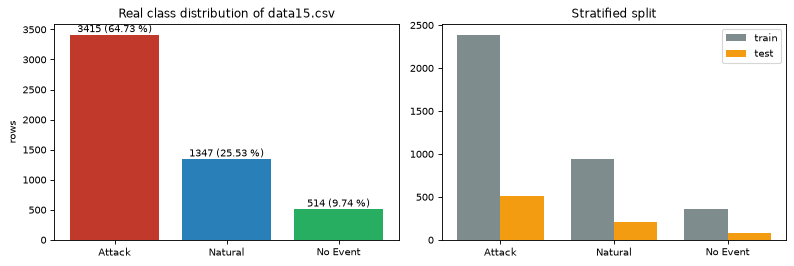

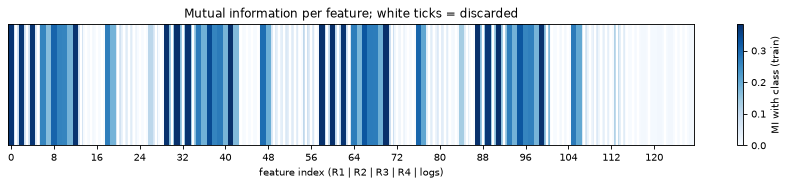

In [6]:
print("shape:", raw.shape, "(rows, 128 features + marker)")
print("original label values:", raw["marker"].value_counts().to_dict())
print("feature groups:", {g: [feat_cols[j] for j in v][:3] + ["..."] for g, v in GROUPS.items()})
print("first 29 feature names (region R1):", feat_cols[:29])
print("last 12 feature names (logs):", feat_cols[-12:])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
cols3 = ["#c0392b", "#2980b9", "#27ae60"]
ax[0].bar(CLASS_NAMES, counts, color=cols3)
for i, c in enumerate(counts):
    ax[0].text(i, c + 40, f"{c} ({100 * c / counts.sum():.2f} %)", ha="center")
ax[0].set_title("Real class distribution of data15.csv"); ax[0].set_ylabel("rows")
tr_counts = np.bincount(y_all[D0["tr"]], minlength=3); te_counts = np.bincount(y_all[D0["te"]], minlength=3)
w = 0.38; x = np.arange(3)
ax[1].bar(x - w / 2, tr_counts, w, label="train", color="#7f8c8d"); ax[1].bar(x + w / 2, te_counts, w, label="test", color="#f39c12")
ax[1].set_xticks(x); ax[1].set_xticklabels(CLASS_NAMES); ax[1].legend(); ax[1].set_title("Stratified split")
plt.tight_layout(); plt.show()

# mutual information of the 128 features (the paper's Fig. 1 heat map), kept features outlined
mi = D0["mi"]; keep = np.zeros(len(mi), bool); keep[D0["sel"]] = True
fig, ax = plt.subplots(figsize=(11, 2.4))
im = ax.imshow(mi[None, :], aspect="auto", cmap="Blues"); ax.set_yticks([])
ax.set_xticks(np.arange(0, 128, 8)); ax.set_xlabel("feature index (R1 | R2 | R3 | R4 | logs)")
for j in np.where(~keep)[0]:
    ax.plot([j, j], [-0.5, 0.5], color="white", lw=2.2)
plt.colorbar(im, ax=ax, label="MI with class (train)"); ax.set_title("Mutual information per feature; white ticks = discarded")
plt.tight_layout(); plt.show()

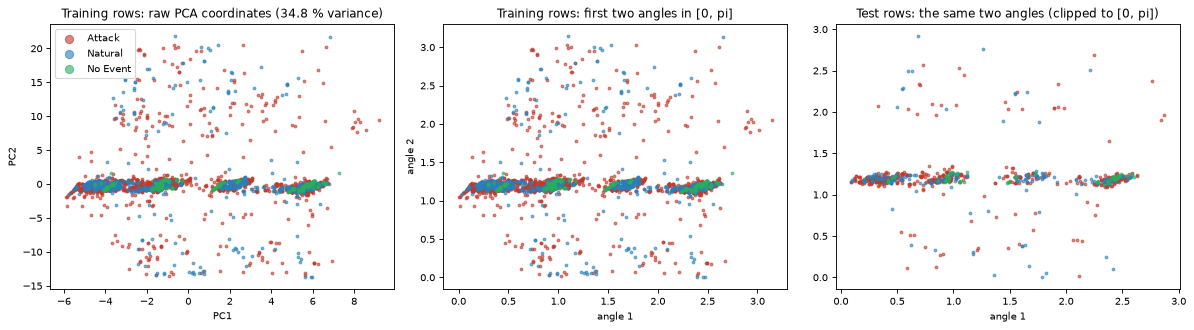

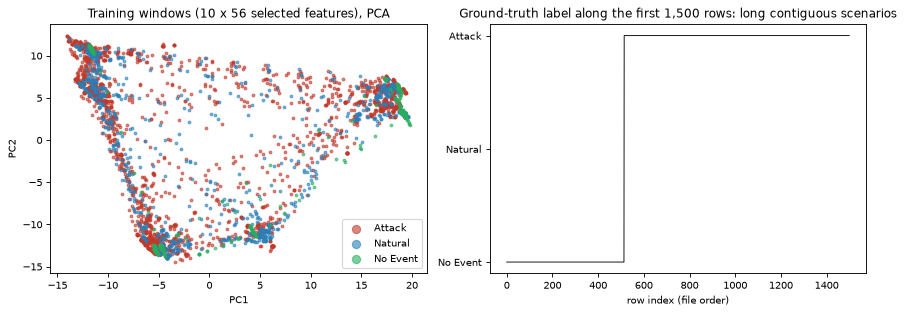

In [7]:
# 2-D PCA of the real training observations (rows, 128 standardised features), coloured by ground-truth class
tr = D0["tr"]
pca2 = PCA(n_components=2, random_state=SEED).fit(D0["Xs"][tr])
P_tr = pca2.transform(D0["Xs"][tr]); y_tr0 = y_all[tr]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for k in range(3):
    m = y_tr0 == k
    ax[0].scatter(P_tr[m, 0], P_tr[m, 1], s=6, alpha=0.6, c=cols3[k], label=CLASS_NAMES[k])
ax[0].set_title(f"Training rows: raw PCA coordinates ({100 * pca2.explained_variance_ratio_.sum():.1f} % variance)")
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(markerscale=3)
# same coordinates scaled to [0, pi] (as an angle-encoding model would see them), test points clipped
mm = MinMaxScaler((0, np.pi)).fit(P_tr)
A_tr = mm.transform(P_tr); A_te = np.clip(mm.transform(pca2.transform(D0["Xs"][D0["te"]])), 0, np.pi)
for k in range(3):
    m = y_tr0 == k
    ax[1].scatter(A_tr[m, 0], A_tr[m, 1], s=6, alpha=0.6, c=cols3[k], label=CLASS_NAMES[k])
ax[1].set_title("Training rows: first two angles in [0, pi]"); ax[1].set_xlabel("angle 1"); ax[1].set_ylabel("angle 2")
yte0 = y_all[D0["te"]]
for k in range(3):
    m = yte0 == k
    ax[2].scatter(A_te[m, 0], A_te[m, 1], s=6, alpha=0.6, c=cols3[k], label=CLASS_NAMES[k])
ax[2].set_title("Test rows: the same two angles (clipped to [0, pi])"); ax[2].set_xlabel("angle 1")
plt.tight_layout(); plt.show()

# time-series view: PCA of the flattened windows of the 56 selected features (what the autoencoder sees)
Wflat = D0["Xwin"].reshape(len(y_all), -1)
pcaw = PCA(n_components=2, random_state=SEED).fit(Wflat[tr])
Pw = pcaw.transform(Wflat[tr])
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k in range(3):
    m = y_tr0 == k
    ax[0].scatter(Pw[m, 0], Pw[m, 1], s=6, alpha=0.6, c=cols3[k], label=CLASS_NAMES[k])
ax[0].set_title("Training windows (10 x 56 selected features), PCA"); ax[0].legend(markerscale=3)
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
ax[1].plot(np.where(y_all == 0, 2, np.where(y_all == 1, 1, 0))[:1500], lw=0.8, color="k")
ax[1].set_yticks([0, 1, 2]); ax[1].set_yticklabels(["No Event", "Natural", "Attack"]); ax[1].set_xlabel("row index (file order)")
ax[1].set_title("Ground-truth label along the first 1,500 rows: long contiguous scenarios")
plt.tight_layout(); plt.show()

## 3. The sparse twin-stream spatiotemporal transformer autoencoder (paper Section 3.2)

Four ingredients, each a few lines of PyTorch:

* **Sparse attention** (Eq. 2): scores `QK^T / sqrt(d_k)`, keep only the `k = 8` largest per query, set the rest to `-inf`, then softmax.
* **Spatial stream** `E_S`: each of the 56 features is a token (its 10-step series projected to `d_model`); attention across features; mean pooling gives `z_s`.
* **Temporal stream** `E_T`: each of the 10 time steps is a token (56 features projected to `d_model`) plus a learnable CLS token; the CLS output is `z_t`.
* **Gated fusion** (Eq. 3) `z_ST = sigmoid(W_g [z_s || z_t]) * z_s + (1 - sigmoid(.)) * z_t`, a multi-head attention encoder and a linear layer to `z in R^32`.

Loss (Eq. 6-7): `MSE(x, x_hat) + lambda * SupCon(z)` with `lambda` ramped up after a warm-up, as in the paper's training schedule.

In [8]:
class SparseAttention(nn.Module):
    """Multi-head attention that keeps only the top-k scores per query (paper Eq. 2)."""
    def __init__(self, d, heads, k, drop):
        super().__init__()
        self.h, self.k, self.dk = heads, k, d // heads
        self.qkv = nn.Linear(d, 3 * d); self.out = nn.Linear(d, d); self.drop = nn.Dropout(drop)
    def forward(self, x):
        B, L, D = x.shape
        q, k, v = self.qkv(x).view(B, L, 3, self.h, self.dk).permute(2, 0, 3, 1, 4)
        sc = q @ k.transpose(-1, -2) / math.sqrt(self.dk)
        kk = min(self.k, L)
        thr = sc.topk(kk, dim=-1).values[..., -1:]
        sc = sc.masked_fill(sc < thr, float("-inf"))               # TopK, the rest -> -inf before softmax
        a = sc.softmax(-1)
        return self.out((a @ v).transpose(1, 2).reshape(B, L, D))

class SparseBlock(nn.Module):
    def __init__(self, d, heads, dff, k, drop):
        super().__init__()
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.att = SparseAttention(d, heads, k, drop)
        self.ff = nn.Sequential(nn.Linear(d, dff), nn.GELU(), nn.Dropout(drop), nn.Linear(dff, d))
        self.drop = nn.Dropout(drop)
    def forward(self, x):
        x = x + self.drop(self.att(self.n1(x)))
        return x + self.drop(self.ff(self.n2(x)))

class STST(nn.Module):
    def __init__(self, T=T_WIN, ds=D_S, d=D_MODEL, heads=N_HEADS, dff=D_FF, dz=D_Z, k=TOPK, drop=DROPOUT):
        super().__init__()
        self.T, self.ds = T, ds
        self.sp_proj = nn.Linear(T, d); self.sp_pos = nn.Parameter(torch.randn(ds, d) * 0.02)
        self.sp_blk = SparseBlock(d, heads, dff, k, drop)
        self.tp_proj = nn.Linear(ds, d); self.tp_pos = nn.Parameter(torch.randn(T + 1, d) * 0.02)
        self.cls = nn.Parameter(torch.zeros(1, 1, d)); self.tp_blk = SparseBlock(d, heads, dff, k, drop)
        self.gate = nn.Linear(2 * d, d)
        self.mha = nn.TransformerEncoderLayer(d, heads, dff, drop, batch_first=True, norm_first=True)
        self.to_z = nn.Linear(d, dz)
        self.dec = nn.Sequential(nn.Linear(dz, dff), nn.GELU(), nn.Linear(dff, T * ds))
    def encode(self, x):                                            # x: [B, T, ds]
        zs = self.sp_blk(self.sp_proj(x.transpose(1, 2)) + self.sp_pos).mean(1)
        t = self.tp_proj(x)
        t = torch.cat([self.cls.expand(len(x), -1, -1), t], 1) + self.tp_pos
        zt = self.tp_blk(t)[:, 0]
        g = torch.sigmoid(self.gate(torch.cat([zs, zt], -1)))
        zst = g * zs + (1 - g) * zt                                  # Eq. 3
        toks = self.mha(torch.stack([zs, zt, zst], 1))               # CHOICE: attention over [z_s, z_t, z_ST]
        return self.to_z(toks[:, 2])
    def forward(self, x):
        z = self.encode(x)
        return z, self.dec(z).view(-1, self.T, self.ds)

def supcon(z, y, tau=TAU):
    """Supervised contrastive loss (Khosla et al., Eq. 7) on L2-normalised embeddings."""
    z = F.normalize(z - z.mean(0, keepdim=True), dim=1); n = len(z)     # CHOICE: batch-centred, otherwise a common offset collapses the loss
    sim = z @ z.T / tau
    self_mask = torch.eye(n, dtype=torch.bool)
    sim = sim.masked_fill(self_mask, float("-inf"))
    logp = sim - torch.logsumexp(sim, dim=1, keepdim=True)
    pos = (y[:, None] == y[None, :]) & ~self_mask
    npos = pos.sum(1)
    ok = npos > 0
    if ok.sum() == 0:
        return z.sum() * 0
    return (-(logp.masked_fill(~pos, 0).sum(1)[ok] / npos[ok])).mean()

def lam_schedule(ep):          # 'warm-up then linearly increasing' (paper: 10 epochs, then 20 epochs)
    if ep < WARMUP_EP: return 0.0
    return LAMBDA_STST * min(1.0, (ep - WARMUP_EP + 1) / RAMP_EP)

def train_stst(D, seed, verbose=True):
    torch.manual_seed(seed); np.random.seed(seed)
    Xw = torch.tensor(D["Xwin"]); yt = torch.tensor(y_all)
    tr, va = D["tr"], D["va"]
    model = STST()
    opt = torch.optim.Adam(model.parameters(), lr=AE_LR, weight_decay=1e-5)
    gen = torch.Generator().manual_seed(seed)
    hist, best, best_state, bad = [], 1e9, None, 0
    t0 = time.time()
    for ep in range(AE_EPOCHS):
        model.train(); lam = lam_schedule(ep)
        perm = torch.tensor(tr)[torch.randperm(len(tr), generator=gen)]
        tl = []
        for i in range(0, len(perm), AE_BATCH):
            b = perm[i:i + AE_BATCH]
            if len(b) < 8: continue
            z, xh = model(Xw[b])
            loss = F.mse_loss(xh, Xw[b]) + lam * supcon(z, yt[b])
            opt.zero_grad(); loss.backward(); opt.step(); tl.append(loss.item())
        model.eval()
        with torch.no_grad():
            zv, xv = model(Xw[va])
            vm = F.mse_loss(xv, Xw[va]).item(); vs = supcon(zv, yt[va]).item()
        vloss = vm + LAMBDA_STST * vs                                # validation loss at the final lambda
        hist.append((ep, lam, float(np.mean(tl)), vm, vs, vloss))
        if ep >= WARMUP_EP + RAMP_EP - 1:                            # patience only counts once lambda is at full value
            if vloss < best - 1e-5:
                best, bad = vloss, 0; best_state = {k: v.clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
        if verbose and (ep % 5 == 0 or ep == AE_EPOCHS - 1):
            print(f"  epoch {ep:3d} lambda {lam:.3f} train {np.mean(tl):.4f} val MSE {vm:.4f} val SupCon {vs:.3f} ({time.time() - t0:.0f}s)")
        if bad >= AE_PATIENCE:
            print(f"  early stop at epoch {ep}"); break
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        Z = torch.cat([model.encode(Xw[i:i + 512]) for i in range(0, len(Xw), 512)]).numpy()
    return model, Z, pd.DataFrame(hist, columns=["epoch", "lambda", "train", "val_mse", "val_supcon", "val_loss"])

n_par = sum(p.numel() for p in STST().parameters())
print(f"STST autoencoder: d_model={D_MODEL}, heads={N_HEADS}, d_ff={D_FF}, latent {D_Z}, trainable parameters {n_par:,}")

STST autoencoder: d_model=32, heads=4, d_ff=64, latent 32, trainable parameters 71,632


## 4. Quantum encodings, simulated exactly (paper Section 3.3)

Three ways to put a 32-dimensional vector on 8 qubits. Because the whole study needs thousands of states and ~10^7 kernel entries, the states are computed by a **vectorised exact state-vector simulation in NumPy** (qubit 0 is the least-significant bit, the Qiskit convention). The next section builds the same circuits in Qiskit, draws them, and **asserts that Qiskit's `Statevector` equals the NumPy state** for random inputs, so the fast code and the drawn circuits are guaranteed to be the same model.

* **Angle** (Eq. 8 + re-uploading): `h in [0,1]`, angle `pi h x s`; qubit `j` gets features `j, j+8, j+16, j+24` through `RY, RZ, RX, RY`; the block is repeated twice.
* **Amplitude** (Eq. 9): L2-normalised vector zero-padded from 32 to 256 amplitudes.
* **IQP** (Eq. 10): `(U_Z(h) H^{x8})^2 |0>`, features scaled to `[-pi, pi] x s`; `U_Z` = 8 single-qubit `RZ(h_j)` and 24 two-qubit `RZZ` on a ring with offsets 1, 2, 3.

In [9]:
NS = 2 ** N_QUBITS
BITS = ((np.arange(NS)[:, None] >> np.arange(N_QUBITS)[None, :]) & 1)       # [256, 8], bit q of basis state
ZS = 1 - 2 * BITS.T                                                          # [8, 256]  z_q = +/-1
IQP_PAIRS = [(j, (j + o) % N_QUBITS) for o in (1, 2, 3) for j in range(N_QUBITS)]
IQP_M = np.concatenate([ZS, np.stack([ZS[a] * ZS[b] for a, b in IQP_PAIRS])], 0).astype(np.float64)   # [32, 256]
WALSH = np.array([[(-1) ** bin(i & j).count("1") for j in range(NS)] for i in range(NS)]) / np.sqrt(NS)
CZ_EDGES = [(q, (q + 1) % N_QUBITS) for q in range(N_QUBITS)]                # ring
CZ_SIGN = np.prod([1 - 2 * (BITS[:, a] & BITS[:, b]) for a, b in CZ_EDGES], 0).astype(np.float32)   # diag of the CZ ring

def _g1(name, th):                       # batched 2x2 gates, th: [B]
    c, s = np.cos(th / 2), np.sin(th / 2); z = np.zeros_like(c, dtype=complex)
    if name == "ry": m = [[c, -s], [s, c]]
    elif name == "rx": m = [[c, -1j * s], [-1j * s, c]]
    else: m = [[np.exp(-1j * th / 2), z], [z, np.exp(1j * th / 2)]]
    return np.array(m, dtype=complex).transpose(2, 0, 1)

def encode_angle(A):
    """A: [B, 32] angles (already pi*h*s). Product state, 2 re-uploading layers."""
    B = len(A); qs = []
    for j in range(N_QUBITS):
        v = np.zeros((B, 2), complex); v[:, 0] = 1
        for _layer in range(2):
            for name, idx in (("ry", j), ("rz", j + 8), ("rx", j + 16), ("ry", j + 24)):
                v = np.einsum("bij,bj->bi", _g1(name, A[:, idx]), v)
        qs.append(v)
    st = qs[N_QUBITS - 1]
    for j in range(N_QUBITS - 2, -1, -1):
        st = (st[:, :, None] * qs[j][:, None, :]).reshape(B, -1)
    return st

def encode_amp(H):
    """H: [B, 32] real. L2-normalised, zero padded to 256 amplitudes."""
    P = np.zeros((len(H), NS), complex); P[:, :H.shape[1]] = H
    return P / np.linalg.norm(P, axis=1, keepdims=True)

def encode_iqp(A):
    """A: [B, 32] angles in [-pi, pi]*s. (U_Z H^n)^2 |0>, U_Z = exp(-i/2 (sum h_j z_j + sum h_jk z_j z_k))."""
    D = np.exp(-0.5j * (A @ IQP_M))                                          # [B, 256] diagonal of U_Z
    st = np.full((len(A), NS), 1 / np.sqrt(NS), complex)                     # H^n |0>
    st = D * st
    st = (st @ WALSH.T)                                                      # second H layer
    return D * st

class EncScaler:
    """Fits on training vectors only; maps a 32-d vector to the angle/amplitude input of an encoding."""
    def __init__(self, kind, H_train, s=1.0):
        self.kind, self.s = kind, s
        if kind == "angle": self.m = MinMaxScaler((0, 1)).fit(H_train)
        elif kind == "iqp": self.m = MinMaxScaler((-1, 1)).fit(H_train)
        else: self.m = StandardScaler().fit(H_train)
    def states(self, H):
        if self.kind == "angle": return encode_angle(np.clip(self.m.transform(H), 0, 1) * np.pi * self.s)
        if self.kind == "iqp": return encode_iqp(np.clip(self.m.transform(H), -1, 1) * np.pi * self.s)
        return encode_amp(self.m.transform(H))

def fidelity_kernel(Sa, Sb):
    return np.abs(Sa.astype(np.complex64) @ Sb.astype(np.complex64).conj().T).astype(np.float64) ** 2                                     # |<phi_a|phi_b>|^2  (Eq. 15)

# quick self-test: states are normalised and a state has kernel 1 with itself
Htest = np.random.default_rng(0).normal(size=(5, 32))
for kind in ENCODINGS:
    S = EncScaler(kind, Htest).states(Htest)
    assert np.allclose(np.linalg.norm(S, axis=1), 1) and np.allclose(np.diag(fidelity_kernel(S, S)), 1)
print("encodings OK:", ENCODINGS)

encodings OK:

 ['angle', 'amplitude', 'iqp']


## Quantum Circuit Architecture

Five distinct gate-based architectures are executed in this study: the **angle**, **amplitude** and **IQP** feature maps (used twice: inside the QDM to build `rho_0`, and in the QSVM kernel `U(h)`), the **QDM reverse-step circuit** `U_t(w_t)` (4 layers of `RX`, `RY` and a CZ ring, 64 trainable angles, five copies with separate weights), and the **fidelity-kernel circuit** `U^dagger(h_i) U(h_j)` whose `|0..0>` probability is the kernel entry. The forward depolarising process of the QDM is a quantum *channel*, not a circuit; it is applied analytically to the density matrix.

For each drawing below the notebook asserts that Qiskit's result equals the fast NumPy/PyTorch simulation used for training (state fidelity > 1 - 1e-9, or equal unitaries). Assumptions where the paper omits circuit details are listed in the table at the top: the 32 features are folded onto 8 qubits (the paper's Eq. 8-10 show one feature per qubit), gate order inside the re-uploading layer, ring offsets of the IQP unitary, and the RX-then-RY order in the QDM layers.

In [10]:
def qc_angle(a):                                    # a: 32 angles (floats or Parameters)
    qc = QuantumCircuit(N_QUBITS, name="angle")
    for layer in range(2):
        for j in range(N_QUBITS):
            qc.ry(a[j], j); qc.rz(a[j + 8], j); qc.rx(a[j + 16], j); qc.ry(a[j + 24], j)
        qc.barrier()
    return qc

def qc_iqp(a):
    qc = QuantumCircuit(N_QUBITS, name="iqp")
    for _rep in range(2):
        qc.h(range(N_QUBITS))
        for j in range(N_QUBITS): qc.rz(a[j], j)
        for i, (p, q) in enumerate(IQP_PAIRS): qc.rzz(a[8 + i], p, q)
        qc.barrier()
    return qc

def qc_amp(vec):
    qc = QuantumCircuit(N_QUBITS, name="amplitude")
    qc.prepare_state(vec / np.linalg.norm(vec), range(N_QUBITS))
    return qc

def qc_pqc(w):                                      # w: [L, n, 2] (RX angle, RY angle)
    qc = QuantumCircuit(N_QUBITS, name="U_t")
    for l in range(QDM_LAYERS):
        for q in range(N_QUBITS): qc.rx(w[l][q][0], q)
        for q in range(N_QUBITS): qc.ry(w[l][q][1], q)
        for a, b in CZ_EDGES: qc.cz(a, b)
        qc.barrier()
    return qc

def bind(qc, pv, vals):
    return qc.assign_parameters(dict(zip(pv, vals)))

rngc = np.random.default_rng(1)
pv = ParameterVector("h", 32)
Hrand = rngc.normal(size=(6, 32))
fid = {}
# ---- angle ----
sc_a = EncScaler("angle", Hrand); A = np.clip(sc_a.m.transform(Hrand), 0, 1) * np.pi
S_np = encode_angle(A)
S_qk = np.array([Statevector(bind(qc_angle(pv), pv, A[i])).data for i in range(len(A))])
fid["angle"] = np.min(np.abs(np.sum(S_np.conj() * S_qk, 1)) ** 2)
# ---- iqp ----
sc_i = EncScaler("iqp", Hrand); Ai = np.clip(sc_i.m.transform(Hrand), -1, 1) * np.pi
S_np = encode_iqp(Ai)
S_qk = np.array([Statevector(bind(qc_iqp(pv), pv, Ai[i])).data for i in range(len(Ai))])
fid["iqp"] = np.min(np.abs(np.sum(S_np.conj() * S_qk, 1)) ** 2)
# ---- amplitude ----
Sam = EncScaler("amplitude", Hrand).states(Hrand)
S_qk = np.array([Statevector(qc_amp(Sam[i].real)).data for i in range(len(Sam))])
fid["amplitude"] = np.min(np.abs(np.sum(Sam.conj() * S_qk, 1)) ** 2)
print("min state fidelity Qiskit vs NumPy:", {k: round(float(v), 12) for k, v in fid.items()})
assert all(v > 1 - 1e-9 for v in fid.values())

min state fidelity Qiskit vs NumPy: {'angle': 1.0, 'iqp': 1.0, 'amplitude': 0.999999999999}


Angle feature map U(h)             qubits 8  depth   8 (transpiled to rx/ry/rz/rzz/cx/cz/h:    8)  trainable parameters 0  free (unbound) parameters 32
IQP feature map U(h)               qubits 8  depth  34 (transpiled to rx/ry/rz/rzz/cx/cz/h:   34)  trainable parameters 0  free (unbound) parameters 32


Amplitude feature map (state prep.) qubits 8  depth   1 (transpiled to rx/ry/rz/rzz/cx/cz/h: 1487)  trainable parameters 0  free (unbound) parameters 0


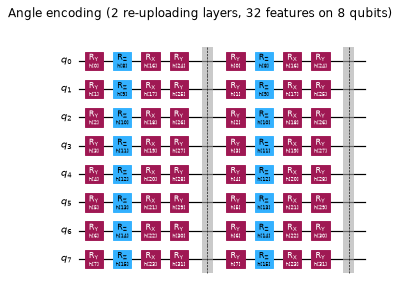

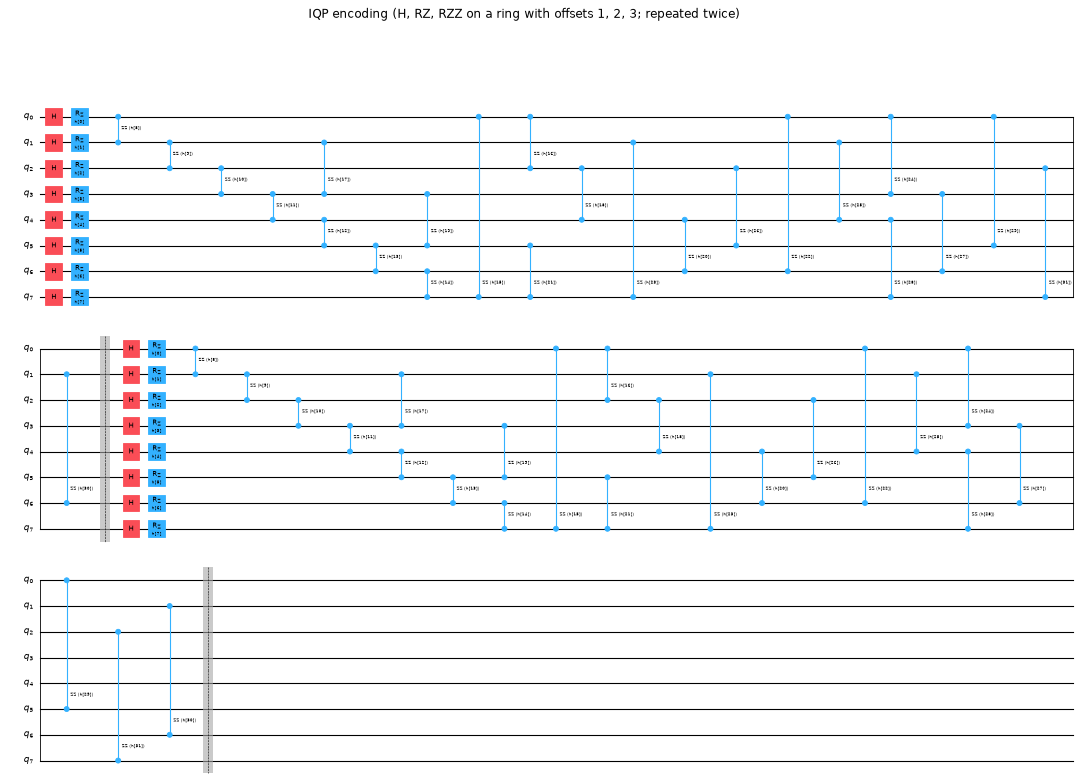

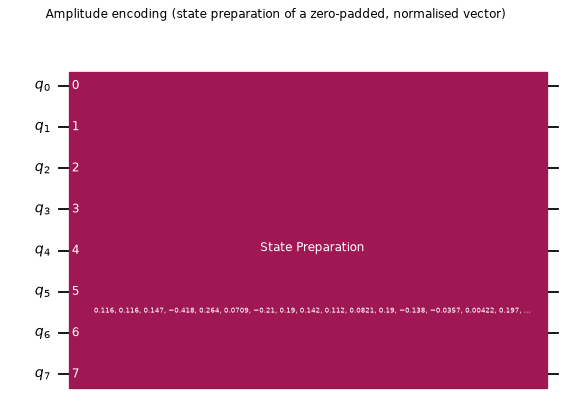

In [11]:
def describe(name, qc, trainable):
    from qiskit import transpile
    dec = transpile(qc, basis_gates=["rx", "ry", "rz", "cx", "cz", "h", "rzz"], optimization_level=0)
    print(f"{name:34s} qubits {qc.num_qubits}  depth {qc.depth():3d} (transpiled to rx/ry/rz/rzz/cx/cz/h: {dec.depth():4d})  "
          f"trainable parameters {trainable}  free (unbound) parameters {qc.num_parameters}")

q_ang, q_iqp = qc_angle(pv), qc_iqp(pv)
qamp = qc_amp(Sam[0].real)
describe("Angle feature map U(h)", q_ang, 0)
describe("IQP feature map U(h)", q_iqp, 0)
describe("Amplitude feature map (state prep.)", qamp, 0)
fig = q_ang.draw("mpl", fold=48, scale=0.55); fig.suptitle("Angle encoding (2 re-uploading layers, 32 features on 8 qubits)"); display(fig); plt.close(fig)
fig = q_iqp.draw("mpl", fold=40, scale=0.5); fig.suptitle("IQP encoding (H, RZ, RZZ on a ring with offsets 1, 2, 3; repeated twice)"); display(fig); plt.close(fig)
fig = qamp.draw("mpl", scale=0.8); fig.suptitle("Amplitude encoding (state preparation of a zero-padded, normalised vector)"); display(fig); plt.close(fig)

max |U_qiskit - U_torch| = 8.81282947448394e-08
QDM reverse step U_t(w_t)          qubits 8  depth  40 (transpiled to rx/ry/rz/rzz/cx/cz/h:   40)  trainable parameters 64  free (unbound) parameters 64
QDM total trainable parameters: 320 (5 circuits)


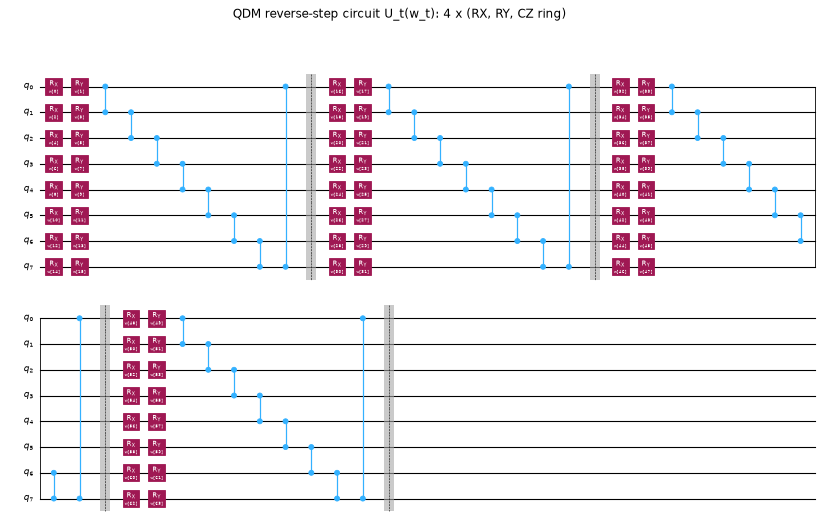

kernel entry via Qiskit |<0|U^dagger(h_i)U(h_j)|0>|^2 = 0.000172   NumPy fidelity kernel = 0.000172
Fidelity-kernel circuit (angle)    qubits 8  depth  16 (transpiled to rx/ry/rz/rzz/cx/cz/h:   16)  trainable parameters 0  free (unbound) parameters 0


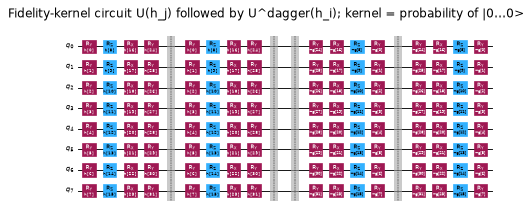

In [12]:
# ---------- the QDM reverse-step circuit U_t(w_t) and its equivalence to the PyTorch simulator used for training ----------
def apply_pqc(params, st):
    """params [Tt, L, n, 2] (RX, RY angles); st [Tt, B, 256] complex. Exact simulation of qc_pqc (qubit 0 = LSB).
    The 8 single-qubit gates of a layer are merged into two 16x16 Kronecker blocks (qubits 0-3 and 4-7)."""
    Tt, L, n, _ = params.shape
    a, b = params[..., 0], params[..., 1]
    ca, sa, cb, sb = torch.cos(a / 2), torch.sin(a / 2), torch.cos(b / 2), torch.sin(b / 2)
    g = torch.stack([torch.stack([cb * ca + 1j * sb * sa, -1j * cb * sa - sb * ca], -1),      # g = RY(b) @ RX(a)
                     torch.stack([sb * ca - 1j * cb * sa, cb * ca - 1j * sb * sa], -1)], -2)  # [Tt, L, n, 2, 2]
    def kron_group(qs):                                  # qs: qubits of the block, highest first
        K = g[:, :, qs[0]]
        for q in qs[1:]:
            d = K.shape[-1]
            K = torch.einsum("tlab,tlcd->tlacbd", K, g[:, :, q]).reshape(Tt, L, 2 * d, 2 * d)
        return K
    h = n // 2
    G_lo, G_hi = kron_group(list(range(h - 1, -1, -1))), kron_group(list(range(n - 1, h - 1, -1)))
    cz = torch.tensor(CZ_SIGN)
    B, dh = st.shape[1], 1 << h
    s = st.reshape(Tt, B, dh, dh)                        # index = hi * 16 + lo
    for l in range(L):
        s = torch.einsum("tac,tbhc->tbha", G_lo[:, l], s)
        s = torch.einsum("tac,tbch->tbah", G_hi[:, l], s)
        s = (s.reshape(Tt, B, NS) * cz).reshape(Tt, B, dh, dh)
    return s.reshape(Tt, B, NS)

def pqc_unitary(w):                                  # w: np [L, n, 2] -> 256x256 unitary
    eye = torch.eye(NS, dtype=torch.complex64)[None]
    out = apply_pqc(torch.tensor(w, dtype=torch.float32)[None], eye)
    return out[0].T.numpy()                           # columns = images of basis states

w_test = rngc.normal(size=(QDM_LAYERS, N_QUBITS, 2))
pv_w = ParameterVector("w", QDM_LAYERS * N_QUBITS * 2)
wq = np.array(pv_w, dtype=object).reshape(QDM_LAYERS, N_QUBITS, 2)
q_pqc = qc_pqc(wq)
U_qk = Operator(q_pqc.assign_parameters(dict(zip(pv_w, w_test.ravel())))).data
U_t = pqc_unitary(w_test)
err = np.abs(U_qk - U_t).max()
print("max |U_qiskit - U_torch| =", float(err)); assert err < 1e-5
describe("QDM reverse step U_t(w_t)", q_pqc, QDM_LAYERS * N_QUBITS * 2)
print("QDM total trainable parameters:", QDM_T * QDM_LAYERS * N_QUBITS * 2, f"({QDM_T} circuits)")
fig = q_pqc.draw("mpl", fold=30, scale=0.5); fig.suptitle("QDM reverse-step circuit U_t(w_t): 4 x (RX, RY, CZ ring)"); display(fig); plt.close(fig)

# ---------- the fidelity-kernel circuit U^dagger(h_i) U(h_j) ----------
i, j = 0, 1
qk = bind(qc_angle(pv), pv, A[j]).compose(bind(qc_angle(pv), pv, A[i]).inverse())
p0 = Statevector(qk).probabilities()[0]
k_np = fidelity_kernel(encode_angle(A[i:i + 1]), encode_angle(A[j:j + 1]))[0, 0]
print(f"kernel entry via Qiskit |<0|U^dagger(h_i)U(h_j)|0>|^2 = {p0:.6f}   NumPy fidelity kernel = {k_np:.6f}")
assert abs(p0 - k_np) < 1e-6        # the kernel code uses complex64 for speed
describe("Fidelity-kernel circuit (angle)", qk, 0)
sym = qc_angle(pv).compose(qc_angle(ParameterVector("g", 32)).inverse())
fig = sym.draw("mpl", fold=60, scale=0.4); fig.suptitle("Fidelity-kernel circuit U(h_j) followed by U^dagger(h_i); kernel = probability of |0...0>"); display(fig); plt.close(fig)

## 5. The quantum diffusion model (paper Section 3.4)

For a pure encoded state `rho_0 = |psi><psi|` the forward process stays inside the span of `rho_0` and the maximally mixed state: after `t` steps `rho_t = a_t rho_0 + (1 - a_t) I/2^n` with `a_t = prod_{s<=t} (1 - gamma_s)` and `gamma_s = gamma_max sin^2(s pi / (2T))` (Eq. 11-12; the cosine schedule `1 - cos^2` equals `sin^2`). Because a unitary maps `I/2^n` to itself, `U_t rho_t U_t^dagger = a_t U_t rho_0 U_t^dagger + (1 - a_t) I/2^n`, so the loss of Eq. 14 and the diagonal of the reconstruction can be computed **exactly from state vectors** (no 256 x 256 matrices per sample). The cell below proves this against a brute-force density-matrix computation.

* **Reconstruction term** (Eq. 14, teacher forcing): `1 - Tr(rho_hat_{t-1} rho_{t-1})`, where `rho_hat_{t-1} = U_t rho_t U_t^dagger`.
* **Separation term** `L_sep = - sum_{c != c'} ||mu_c - mu_c'||^2` of the class centroids of `diag(rho_hat_0)`, with `rho_hat_0` obtained by chaining the five circuits on `rho_T`, weight `lambda_QDM = 0.001`.
* **Output.** `diag(rho_hat_0)` (256 probabilities) -> linear map (PCA, see the table at the top) -> `h in R^32`.

In [13]:
GAM = GAMMA_MAX * np.sin(np.arange(1, QDM_T + 1) * np.pi / (2 * QDM_T)) ** 2          # gamma_1 ... gamma_T
A_CUM = np.concatenate([[1.0], np.cumprod(1 - GAM)])                                    # a_0 = 1, a_t
print("gamma_t:", np.round(GAM, 3), "| signal fraction a_t:", np.round(A_CUM, 4))

def qdm_loss_terms(params, psi, y):
    """psi [B, 256] complex64, y [B] ints. Returns (reconstruction, separation, diag of rho_hat_0 [B, 256])."""
    Tt = QDM_T
    st = psi[None].expand(Tt, -1, -1).contiguous()
    phi = apply_pqc(params, st)                                                         # U_t |psi>   [T, B, 256]
    o = (psi.conj()[None] * phi).sum(-1).abs() ** 2                                     # |<psi|U_t psi>|^2  [T, B]
    a_t = torch.tensor(A_CUM[1:], dtype=torch.float32)[:, None]
    a_p = torch.tensor(A_CUM[:-1], dtype=torch.float32)[:, None]
    tr = a_t * a_p * o + (a_t * (1 - a_p) + (1 - a_t) * a_p + (1 - a_t) * (1 - a_p)) / NS   # Tr(rho_hat_{t-1} rho_{t-1})
    rec = (1 - tr).mean()
    ch = psi[None]
    for t in range(Tt - 1, -1, -1):                                                     # chain U_1 ... U_T on rho_T
        ch = apply_pqc(params[t:t + 1], ch)
    diag = A_CUM[-1] * ch[0].abs() ** 2 + (1 - A_CUM[-1]) / NS
    sep = psi.new_zeros((), dtype=torch.float32)
    cls = [c for c in torch.unique(y).tolist()]
    mus = {c: diag[y == c].mean(0) for c in cls}
    for c in cls:
        for c2 in cls:
            if c != c2: sep = sep - ((mus[c] - mus[c2]) ** 2).sum()
    return rec, sep, diag

# ---- proof that the analytic shortcut equals brute-force density matrices ----
torch.manual_seed(0)
p_chk = torch.randn(QDM_T, QDM_LAYERS, N_QUBITS, 2) * 0.7
psi_chk = torch.tensor(encode_angle(rngc.uniform(0, np.pi, (3, 32))), dtype=torch.complex64)
rec_a, _, diag_a = qdm_loss_terms(p_chk, psi_chk, torch.tensor([0, 1, 2]))
rec_b, diag_b = [], []
for b in range(3):
    rho = torch.outer(psi_chk[b], psi_chk[b].conj()); rho_prev = rho.clone(); rhos = [rho]
    for t in range(QDM_T):
        rho = (1 - float(GAM[t])) * rho + float(GAM[t]) * torch.eye(NS) / NS; rhos.append(rho)
    terms = []
    for t in range(1, QDM_T + 1):
        U = torch.tensor(pqc_unitary(p_chk[t - 1].numpy()))
        rhat = U @ rhos[t] @ U.conj().T
        terms.append(1 - (rhat @ rhos[t - 1]).trace().real)
    rec_b.append(torch.stack(terms).mean())
    rr = rhos[-1]
    for t in range(QDM_T - 1, -1, -1):
        U = torch.tensor(pqc_unitary(p_chk[t].numpy())); rr = U @ rr @ U.conj().T
    diag_b.append(torch.diagonal(rr).real)
print("reconstruction term: analytic", float(rec_a), "| brute force", float(torch.stack(rec_b).mean()))
assert abs(float(rec_a) - float(torch.stack(rec_b).mean())) < 1e-5 and torch.allclose(diag_a, torch.stack(diag_b), atol=1e-6)

def train_qdm(psi_tr, y_tr, seed, verbose=True):
    torch.manual_seed(seed)
    params = nn.Parameter(0.1 * torch.randn(QDM_T, QDM_LAYERS, N_QUBITS, 2))      # CHOICE: small random initial angles
    opt = torch.optim.Adam([params], lr=QDM_LR)
    psi = torch.tensor(psi_tr, dtype=torch.complex64); yy = torch.tensor(y_tr)
    gen = torch.Generator().manual_seed(seed); hist = []
    for ep in range(QDM_EPOCHS):
        perm = torch.randperm(len(psi), generator=gen); r_, s_ = [], []
        for i in range(0, len(perm) - QDM_BATCH + 1, QDM_BATCH):
            b = perm[i:i + QDM_BATCH]
            rec, sep, _ = qdm_loss_terms(params, psi[b], yy[b])
            loss = rec + LAMBDA_QDM * sep
            opt.zero_grad(); loss.backward(); opt.step(); r_.append(rec.item()); s_.append(sep.item())
        hist.append((ep, float(np.mean(r_)), float(np.mean(s_))))
        if verbose and (ep % 5 == 0 or ep == QDM_EPOCHS - 1):
            print(f"    QDM epoch {ep:2d}  reconstruction {np.mean(r_):.5f}  L_sep {np.mean(s_):.5f}")
    return params.detach(), pd.DataFrame(hist, columns=["epoch", "rec", "sep"])

@torch.no_grad()
def qdm_refine(params, psi_all):
    out = []
    for i in range(0, len(psi_all), 1024):
        psi = torch.tensor(psi_all[i:i + 1024], dtype=torch.complex64)
        ch = psi[None]
        for t in range(QDM_T - 1, -1, -1): ch = apply_pqc(params[t:t + 1], ch)
        out.append((A_CUM[-1] * ch[0].abs() ** 2 + (1 - A_CUM[-1]) / NS).numpy())
    return np.concatenate(out)                                                       # diag(rho_hat_0)  [N, 256]

gamma_t: [0.072 0.259 0.491 0.678 0.75 ] | signal fraction a_t: [1.     0.9284 0.6878 0.3502 0.1126 0.0282]


reconstruction term: analytic 0.9916593432426453 | brute force 0.9916593432426453


## 6. Run the whole STQD pipeline (paper Algorithm 1)

For each seed the function below runs: split -> preprocessing -> MI selection -> STST autoencoder -> for each encoding: encode `z`, train the QDM, refine with the 5 learned circuits, PCA to 32 dimensions -> fidelity-kernel QSVM over the grid `C` x bandwidth. It also trains the **ablations** (the same QSVM directly on `z`, i.e. without the QDM; an RBF-SVM on `z` and on the QDM output) and the **classical baselines** on the same split: random forest on all 128 features of the last row, random forest on the flattened 10 x 56 windows, RBF-SVM on the 56 selected features, and the paper's strongest baseline RFE-RF (recursive feature elimination to 50 features, then a random forest, Zaman et al. 2023).

In [14]:
def metr(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="weighted", zero_division=0)
    return dict(acc=accuracy_score(y, p), prec=pr, rec=rc, f1=f1)

def qsvm_rows(Hfeat, enc, tag, tr, va, te, seed, preds):
    """Fidelity-kernel QSVM over the (bandwidth, C) grid. Kernel built from exact state vectors (see Section 4)."""
    ytr, yva, yte = y_all[tr], y_all[va], y_all[te]; rows = []
    for s in (BANDWIDTHS if enc != "amplitude" else [1.0]):
        S = EncScaler(enc, Hfeat[tr], s).states(Hfeat)
        Ktr, Kva, Kte = fidelity_kernel(S[tr], S[tr]), fidelity_kernel(S[va], S[tr]), fidelity_kernel(S[te], S[tr])
        for C in C_GRID:
            clf = SVC(kernel="precomputed", C=C, decision_function_shape="ovo", random_state=seed).fit(Ktr, ytr)
            pv_, pt_ = clf.predict(Kva), clf.predict(Kte)
            rows.append(dict(model=tag, enc=enc, s=s, C=C, val_f1=metr(yva, pv_)["f1"], **metr(yte, pt_)))
            preds[(tag, enc, s, C)] = pt_
    return rows

def run_seed(seed, mode="random", verbose=True, ablate=True):
    t0 = time.time()
    D = D0 if (seed == SEED and mode == "random") else prepare(seed, mode)
    tr, va, te = D["tr"], D["va"], D["te"]; ytr, yva, yte = y_all[tr], y_all[va], y_all[te]
    if verbose: print(f"[seed {seed}, {mode} split] train/val/test = {len(tr)}/{len(va)}/{len(te)}; training the STST autoencoder")
    t_ae = time.time()
    model, Z, ae_hist = train_stst(D, seed, verbose)
    t_ae = time.time() - t_ae
    R = dict(seed=seed, mode=mode, D=D, Z=Z, ae_hist=ae_hist, rows=[], preds={}, qdm_hist={}, H={}, base=[], time_ae=t_ae, time_qdm={})
    for enc in ENCODINGS:
        t_q = time.time()
        psi_all = EncScaler(enc, Z[tr], 1.0).states(Z)                       # E(z): states that form rho_0
        if verbose: print(f"  [{enc}] training the QDM ({QDM_T} circuits x {QDM_LAYERS} layers, {QDM_EPOCHS} epochs)")
        params, qh = train_qdm(psi_all[tr], ytr, seed, verbose)
        diag = qdm_refine(params, psi_all)                                  # diag(rho_hat_0)
        Hq = PCA(D_Z, random_state=seed).fit(diag[tr]).transform(diag)      # CHOICE: linear layer = PCA fitted on train
        R["qdm_hist"][enc] = qh; R["H"][enc] = Hq
        R["rows"] += qsvm_rows(Hq, enc, "STQD", tr, va, te, seed, R["preds"])      # the paper's pipeline
        if ablate:
            R["rows"] += qsvm_rows(Z, enc, "QSVM on z (no QDM)", tr, va, te, seed, R["preds"])   # ablation
        R["time_qdm"][enc] = time.time() - t_q
    # ---- classical baselines on the same split ----
    Xs, rows_sel, Xw = D["Xs"], D["rows_sel"], D["Xwin"]
    def add(name, p): R["base"].append(dict(model=name, **metr(yte, p)))
    Zs = StandardScaler().fit(Z[tr]).transform(Z)
    Hs = StandardScaler().fit(R["H"]["angle"][tr]).transform(R["H"]["angle"])
    add("RF, 128 features (last row)", RandomForestClassifier(200, random_state=seed, n_jobs=2).fit(Xs[tr], ytr).predict(Xs[te]))
    add("RF, 10x56 window", RandomForestClassifier(200, random_state=seed, n_jobs=2).fit(Xw[tr].reshape(len(tr), -1), ytr).predict(Xw[te].reshape(len(te), -1)))
    add("SVC rbf, 56 selected features", SVC(C=10, random_state=seed).fit(rows_sel[tr], ytr).predict(rows_sel[te]))
    rfe = RFE(RandomForestClassifier(60, random_state=seed, n_jobs=2), n_features_to_select=50, step=20).fit(Xs[tr], ytr)
    add("RFE-RF, 50 features (Zaman et al.)", RandomForestClassifier(200, random_state=seed, n_jobs=2).fit(Xs[tr][:, rfe.support_], ytr).predict(Xs[te][:, rfe.support_]))
    add("SVC rbf on STST latent z", SVC(C=10, random_state=seed).fit(Zs[tr], ytr).predict(Zs[te]))
    add("SVC rbf on QDM output h (angle)", SVC(C=10, random_state=seed).fit(Hs[tr], ytr).predict(Hs[te]))
    R["time_total"] = time.time() - t0
    if verbose: print(f"  seed {seed} finished in {R['time_total'] / 60:.1f} min (autoencoder {t_ae / 60:.1f} min, QDM+QSVM {sum(R['time_qdm'].values()) / 60:.1f} min)")
    return R

RES = {}
for sd in SEEDS:
    RES[sd] = run_seed(sd, "random", verbose=(sd == SEEDS[0]))
R0 = RES[SEEDS[0]]
print("total wall-clock for", len(SEEDS), "seed(s):", round(sum(r["time_total"] for r in RES.values()) / 60, 1), "min")

[seed 42, random split] train/val/test = 3693/791/792; training the STST autoencoder


  epoch   0 lambda 0.000 train 0.7066 val MSE 0.5375 val SupCon 18.093 (13s)


  epoch   5 lambda 0.060 train 1.0356 val MSE 0.3629 val SupCon 14.745 (77s)


  epoch  10 lambda 0.100 train 1.1974 val MSE 0.3348 val SupCon 14.357 (158s)


  epoch  15 lambda 0.100 train 1.1233 val MSE 0.2924 val SupCon 13.914 (247s)


...

    QDM epoch  5  reconstruction 0.62746  L_sep -0.00006


  [iqp] training the QDM (5 circuits x 4 layers, 6 epochs)


    QDM epoch  0  reconstruction 0.63372  L_sep -0.00000


    QDM epoch  5  reconstruction 0.62746  L_sep -0.00000


  seed 42 finished in 11.7 min (autoencoder 7.5 min, QDM+QSVM 3.4 min)
total wall-clock for 1 seed(s): 11.7 min


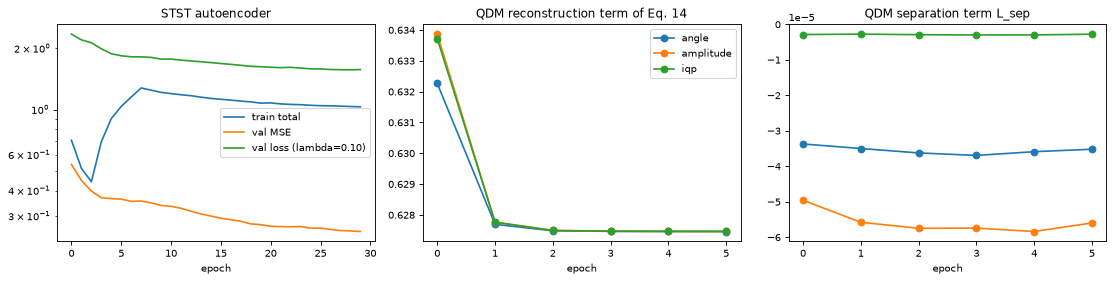

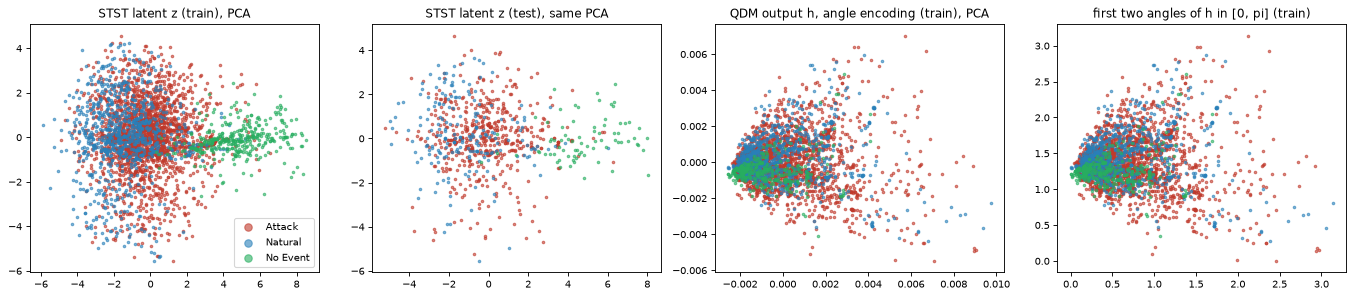

In [15]:
# training curves of the first seed: autoencoder and the three QDMs
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
h = R0["ae_hist"]
ax[0].plot(h.epoch, h.train, label="train total"); ax[0].plot(h.epoch, h.val_mse, label="val MSE"); ax[0].plot(h.epoch, h.val_loss, label="val loss (lambda=0.10)")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].legend(); ax[0].set_title("STST autoencoder")
for enc in ENCODINGS:
    q = R0["qdm_hist"][enc]; ax[1].plot(q.epoch, q.rec, marker="o", label=enc); ax[2].plot(q.epoch, q.sep, marker="o", label=enc)
ax[1].set_title("QDM reconstruction term of Eq. 14"); ax[1].set_xlabel("epoch"); ax[1].legend()
ax[2].set_title("QDM separation term L_sep"); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.show()

# how the representation evolves: real test+train points coloured by ground truth
tr, te = R0["D"]["tr"], R0["D"]["te"]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
def scat(a, P, idx, title):
    for k in range(3):
        m = y_all[idx] == k
        a.scatter(P[m, 0], P[m, 1], s=5, alpha=0.6, c=cols3[k], label=CLASS_NAMES[k])
    a.set_title(title)
pz = PCA(2, random_state=SEED).fit(R0["Z"][tr]); scat(ax[0], pz.transform(R0["Z"][tr]), tr, "STST latent z (train), PCA"); ax[0].legend(markerscale=3)
scat(ax[1], pz.transform(R0["Z"][te]), te, "STST latent z (test), same PCA")
Hq = R0["H"]["angle"]; ph = PCA(2, random_state=SEED).fit(Hq[tr]); scat(ax[2], ph.transform(Hq[tr]), tr, "QDM output h, angle encoding (train), PCA")
mmh = MinMaxScaler((0, np.pi)).fit(Hq[tr][:, :2]); scat(ax[3], mmh.transform(Hq[tr][:, :2]), tr, "first two angles of h in [0, pi] (train)")
plt.tight_layout(); plt.show()

## 7. Results: Table 3 redrawn, hyper-parameter choice and the confusion matrix (paper Sections 5.1 and 5.4)

* **Table 3 (paper-faithful).** Kernel bandwidth `s = 1` (the paper has no bandwidth) and all `C`; test metrics, mean +/- std over the seeds.
* **Two ways to pick a cell.** The paper shows all nine cells and reports the best one on the test set (optimistic, because it uses test labels to choose). We also report the cell chosen on the *validation* split, including the bandwidth `s`.

Table 3 redrawn (QSVM on QDM-refined features, test set, bandwidth s = 1, mean over seeds [42] )
 Encoding    C  Acc (paper)  Acc (here)  Acc std  F1 (paper)  F1 (here)  F1 std  F1 gap
    angle 10.0       0.9533      0.7323      NaN      0.9529     0.7085     NaN -0.2444
    angle  1.0       0.9407      0.7033      NaN      0.9408     0.6214     NaN -0.3194
    angle  0.1       0.9369      0.6818      NaN      0.9377     0.5712     NaN -0.3665
amplitude 10.0       0.9457      0.7866      NaN      0.9453     0.7799     NaN -0.1654
amplitude  1.0       0.9369      0.7917      NaN      0.9374     0.7726     NaN -0.1648
amplitude  0.1       0.9343      0.6995      NaN      0.9353     0.6048     NaN -0.3305
      iqp 10.0       0.9407      0.7525      NaN      0.9399     0.7291     NaN -0.2108
      iqp  1.0       0.9268      0.7437      NaN      0.9262     0.6962     NaN -0.2300
      iqp  0.1       0.9028      0.6553      NaN      0.9027     0.5264     NaN -0.3763
cells within 0.02 F1 of

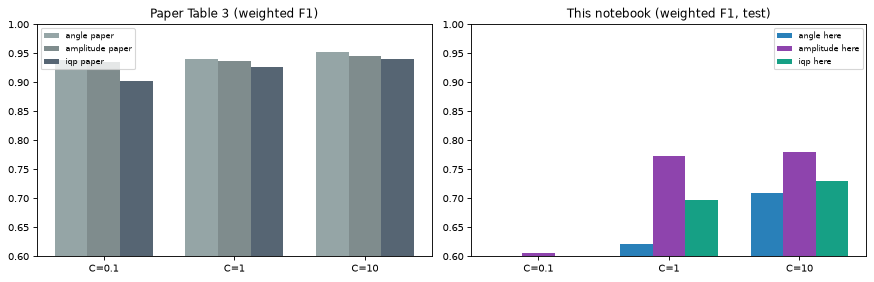

In [16]:
ALL = pd.concat([pd.DataFrame(r["rows"]).assign(seed=sd) for sd, r in RES.items()], ignore_index=True)
PAPER_T3 = {  # (enc, C): (acc, prec, rec, f1)  -- paper Table 3
    ("angle", 10.0): (0.9533, 0.9534, 0.9533, 0.9529), ("angle", 1.0): (0.9407, 0.9420, 0.9407, 0.9408), ("angle", 0.1): (0.9369, 0.9403, 0.9369, 0.9377),
    ("amplitude", 10.0): (0.9457, 0.9454, 0.9457, 0.9453), ("amplitude", 1.0): (0.9369, 0.9395, 0.9369, 0.9374), ("amplitude", 0.1): (0.9343, 0.9386, 0.9343, 0.9353),
    ("iqp", 10.0): (0.9407, 0.9410, 0.9407, 0.9399), ("iqp", 1.0): (0.9268, 0.9265, 0.9268, 0.9262), ("iqp", 0.1): (0.9028, 0.9035, 0.9028, 0.9027)}
st = ALL[(ALL.model == "STQD") & (ALL.s == 1.0)].groupby(["enc", "C"])[["acc", "prec", "rec", "f1"]].agg(["mean", "std"])
T3 = []
for (enc, C), (pa, pp, pr_, pf) in PAPER_T3.items():
    g = st.loc[(enc, C)]
    T3.append(dict(Encoding=enc, C=C, **{"Acc (paper)": pa, "Acc (here)": g[("acc", "mean")], "Acc std": g[("acc", "std")],
                   "F1 (paper)": pf, "F1 (here)": g[("f1", "mean")], "F1 std": g[("f1", "std")], "F1 gap": g[("f1", "mean")] - pf}))
T3 = pd.DataFrame(T3)
pd.set_option("display.width", 200)
print("Table 3 redrawn (QSVM on QDM-refined features, test set, bandwidth s = 1, mean over seeds", SEEDS, ")")
print(T3.round(4).to_string(index=False))
print("cells within 0.02 F1 of the paper:", int((T3["F1 gap"].abs() <= 0.02).sum()), "/ 9")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6)); w = 0.25
for k, enc in enumerate(ENCODINGS):
    d = T3[T3.Encoding == enc].sort_values("C")
    ax[0].bar(np.arange(3) + (k - 1) * w, d["F1 (paper)"], w, color=["#95a5a6", "#7f8c8d", "#566573"][k], label=f"{enc} paper")
    ax[1].bar(np.arange(3) + (k - 1) * w, d["F1 (here)"], w, yerr=d["F1 std"].fillna(0), color=["#2980b9", "#8e44ad", "#16a085"][k], label=f"{enc} here")
for a, t in zip(ax, ["Paper Table 3 (weighted F1)", "This notebook (weighted F1, test)"]):
    a.set_xticks(range(3)); a.set_xticklabels(["C=0.1", "C=1", "C=10"]); a.set_ylim(0.6, 1.0); a.set_title(t); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

best cell on the TEST set (paper protocol, s=1): ('amplitude', np.float64(10.0)) -> acc 0.7866  F1 0.7799
cell chosen on the VALIDATION split per seed (enc, s, C): [('amplitude', 1.0, 10.0)]
  -> test acc 0.7866 +/- 0.0000  F1 0.7799 +/- 0.0000
      enc     F1    acc        chosen
    angle 0.7085 0.7323 [(1.0, 10.0)]
amplitude 0.7799 0.7866 [(1.0, 10.0)]
      iqp 0.7267 0.7386 [(0.5, 10.0)]


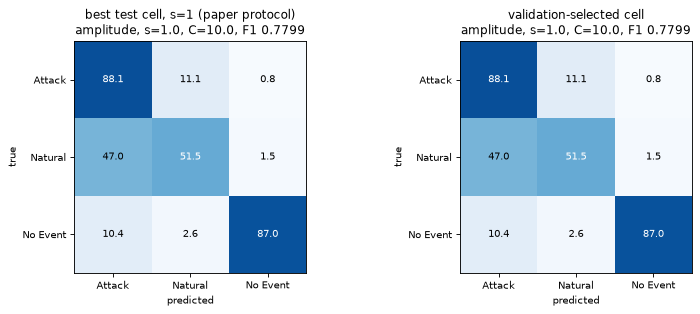

per-class recall (%) of the best-test cell: {'Attack': np.float64(88.11), 'Natural': np.float64(51.49), 'No Event': np.float64(87.01)} | paper: Attack 98.25, Natural 88.61, No Event 93.51


In [17]:
# ---- two selection protocols for the full pipeline ----
S1 = ALL[(ALL.model == "STQD")]
mean_s1 = S1[S1.s == 1.0].groupby(["enc", "C"])[["acc", "prec", "rec", "f1"]].mean()
best_test = mean_s1["f1"].idxmax()
print("best cell on the TEST set (paper protocol, s=1):", best_test, "-> acc %.4f  F1 %.4f" % (mean_s1.loc[best_test, "acc"], mean_s1.loc[best_test, "f1"]))
val_sel = []
for sd, g in S1.groupby("seed"):
    b = g.loc[g.val_f1.idxmax()]; val_sel.append(b)
val_sel = pd.DataFrame(val_sel)
print("cell chosen on the VALIDATION split per seed (enc, s, C):", [(r.enc, r.s, r.C) for r in val_sel.itertuples()])
print("  -> test acc %.4f +/- %.4f  F1 %.4f +/- %.4f" % (val_sel.acc.mean(), val_sel.acc.std(ddof=0), val_sel.f1.mean(), val_sel.f1.std(ddof=0)))
# per-encoding validation-selected result
rows = []
for enc in ENCODINGS:
    r_ = []
    for sd, g in S1[S1.enc == enc].groupby("seed"):
        b = g.loc[g.val_f1.idxmax()]; r_.append(b)
    r_ = pd.DataFrame(r_); rows.append(dict(enc=enc, F1=r_.f1.mean(), acc=r_.acc.mean(), chosen=[(x.s, x.C) for x in r_.itertuples()]))
print(pd.DataFrame(rows).round(4).to_string(index=False))

# ---- confusion matrices (seed of the first run) ----
te = R0["D"]["te"]; yte = y_all[te]
def conf_of(key):
    return confusion_matrix(yte, R0["preds"][key], labels=[0, 1, 2])
b0 = R0["rows"]; g0 = pd.DataFrame(b0); g0 = g0[(g0.model == "STQD")]
kt = g0[g0.s == 1.0].loc[g0[g0.s == 1.0].f1.idxmax()]; kv = g0.loc[g0.val_f1.idxmax()]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, k_, ttl in zip(ax, [kt, kv], ["best test cell, s=1 (paper protocol)", "validation-selected cell"]):
    cm = conf_of(("STQD", k_.enc, k_.s, k_.C)); cmn = 100 * cm / cm.sum(1, keepdims=True)
    a.imshow(cmn, cmap="Blues", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3): a.text(j, i, f"{cmn[i, j]:.1f}", ha="center", va="center", color="white" if cmn[i, j] > 50 else "black")
    a.set_xticks(range(3)); a.set_yticks(range(3)); a.set_xticklabels(CLASS_NAMES); a.set_yticklabels(CLASS_NAMES)
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(f"{ttl}\n{k_.enc}, s={k_.s}, C={k_.C}, F1 {k_.f1:.4f}")
plt.tight_layout(); plt.show()
recall_best = 100 * np.diag(conf_of(("STQD", kt.enc, kt.s, kt.C))) / np.bincount(yte, minlength=3)
print("per-class recall (%) of the best-test cell:", dict(zip(CLASS_NAMES, np.round(recall_best, 2))), "| paper: Attack 98.25, Natural 88.61, No Event 93.51")

In [18]:
# ---- ablations and classical baselines (same split, test set) ----
A_ = ALL[ALL.model == "QSVM on z (no QDM)"]
abl = A_[A_.s == 1.0].groupby(["enc", "C"])["f1"].mean().unstack()
full = S1[S1.s == 1.0].groupby(["enc", "C"])["f1"].mean().unstack()
print("Weighted F1, QSVM with the QDM (paper pipeline):"); print(full.round(4).to_string())
print("Weighted F1, QSVM directly on the STST latent z (no QDM):"); print(abl.round(4).to_string())
BASE = pd.concat([pd.DataFrame(r["base"]).assign(seed=sd) for sd, r in RES.items()])
bt = BASE.groupby("model")[["acc", "prec", "rec", "f1"]].agg(["mean", "std"]).round(4)
print("\nClassical baselines on the identical split (mean over seeds):"); print(bt.to_string())

Weighted F1, QSVM with the QDM (paper pipeline):
C            0.1     1.0     10.0
enc                              
amplitude  0.6048  0.7726  0.7799
angle      0.5712  0.6214  0.7085
iqp        0.5264  0.6962  0.7291
Weighted F1, QSVM directly on the STST latent z (no QDM):
C            0.1     1.0     10.0
enc                              
amplitude  0.6082  0.7694  0.8123
angle      0.5953  0.7402  0.8118
iqp        0.5425  0.7613  0.8172

Classical baselines on the identical split (mean over seeds):
                                       acc        prec         rec          f1    
                                      mean std    mean std    mean std    mean std
model                                                                             
RF, 10x56 window                    0.9659 NaN  0.9676 NaN  0.9659 NaN  0.9654 NaN
RF, 128 features (last row)         0.9470 NaN  0.9478 NaN  0.9470 NaN  0.9460 NaN
RFE-RF, 50 features (Zaman et al.)  0.9571 NaN  0.9572 NaN  0.9571 NaN  0.9

## 8. Robustness: a leakage-free blocked split

Consecutive rows of `data15.csv` come from long contiguous scenarios and neighbouring windows overlap in 9 of 10 rows, so a random window split puts near-copies of training windows into the test set. As a robustness check, the same pipeline is run once with a **blocked split**: windows are cut into contiguous blocks of 100, whole blocks go to train / validation / test (70 / 15 / 15 %), and the 9 windows at the start of each block (which overlap the previous block) are purged. This is *not* the paper's protocol; it measures how much of the accuracy is generalisation to unseen stretches of the grid trace.

blocked split sizes train/val/test: 3343 728 728 | test class counts [424, 122, 182]
STQD, blocked split: best-test cell (s=1) amplitude C=1.0 F1 0.4866 acc 0.5288 | validation-selected angle s=1.0 C=1.0 F1 0.4696 acc 0.5302
Baselines, blocked split:
                                       acc      f1
model                                             
RF, 128 features (last row)         0.4986  0.4421
RF, 10x56 window                    0.4945  0.4425
SVC rbf, 56 selected features       0.5234  0.4702
RFE-RF, 50 features (Zaman et al.)  0.4945  0.4395
SVC rbf on STST latent z            0.5330  0.4960
SVC rbf on QDM output h (angle)     0.5343  0.4806
                                    random split F1  blocked split F1
STQD (best test cell)                        0.7799            0.4866
RF, 128 features (last row)                  0.9460            0.4421
RF, 10x56 window                             0.9654            0.4425
SVC rbf, 56 selected features                0.6989          

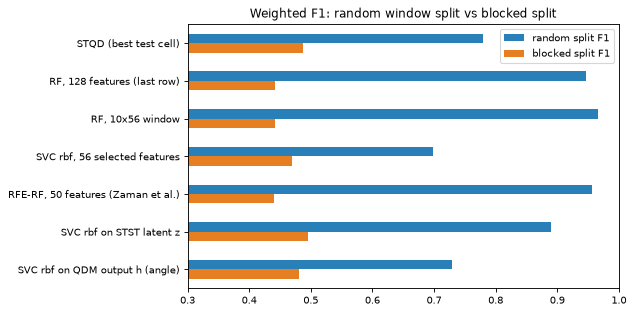

In [19]:
if RUN_BLOCK_CHECK:
    RB = run_seed(SEED, "block", verbose=False, ablate=False)
    Db = RB["D"]; print("blocked split sizes train/val/test:", len(Db["tr"]), len(Db["va"]), len(Db["te"]),
                        "| test class counts", np.bincount(y_all[Db["te"]], minlength=3).tolist())
    Bk = pd.DataFrame(RB["rows"]); Bk = Bk[(Bk.model == "STQD")]
    kb = Bk[Bk.s == 1.0].loc[Bk[Bk.s == 1.0].f1.idxmax()]; kvb = Bk.loc[Bk.val_f1.idxmax()]
    print("STQD, blocked split: best-test cell (s=1) %s C=%s F1 %.4f acc %.4f | validation-selected %s s=%s C=%s F1 %.4f acc %.4f" %
          (kb.enc, kb.C, kb.f1, kb.acc, kvb.enc, kvb.s, kvb.C, kvb.f1, kvb.acc))
    bb = pd.DataFrame(RB["base"]).set_index("model")[["acc", "f1"]]
    print("Baselines, blocked split:"); print(bb.round(4).to_string())
    cmp = pd.DataFrame({"random split F1": [kt.f1, *[BASE[BASE.model == m].f1.mean() for m in bb.index]],
                        "blocked split F1": [kb.f1, *bb.f1.values]}, index=["STQD (best test cell)", *bb.index])
    print(cmp.round(4).to_string())
    ax = cmp.plot.barh(figsize=(8, 4), color=["#2980b9", "#e67e22"]); ax.set_xlim(0.3, 1.0); ax.invert_yaxis(); ax.set_title("Weighted F1: random window split vs blocked split")
    plt.tight_layout(); plt.show()
else:
    RB = None; print("blocked-split check skipped")

## 9. Paper versus this notebook: one verdict per claim

Rule: **reproduced** if the gap is within 0.02 weighted F1 (2 accuracy points), **exceeded** if we are higher by more, **not reached** if lower by more, **cannot be checked** if the data or code are not available.

In [20]:
def verdict(paper, here, tol=0.02):
    d = here - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

f1c = lambda e, C: float(mean_s1.loc[(e, C), "f1"])
ang_gt = all(f1c("angle", C) > max(f1c("amplitude", C), f1c("iqp", C)) for C in C_GRID)
inc_C = all(f1c(e, 0.1) <= f1c(e, 1.0) <= f1c(e, 10.0) + 1e-9 for e in ENCODINGS)
iqp_weak = f1c("iqp", 0.1) == min(float(v) for v in mean_s1["f1"])
rfe_f1 = BASE[BASE.model.str.startswith("RFE-RF")].f1.mean()
rcl = dict(zip(CLASS_NAMES, recall_best))
claims = [
    ("Table 3: Angle, C=10, weighted F1", 0.9529, f1c("angle", 10.0), verdict(0.9529, f1c("angle", 10.0))),
    ("Table 3: Angle, C=10, accuracy", 0.9533, float(mean_s1.loc[("angle", 10.0), "acc"]), verdict(0.9533, float(mean_s1.loc[("angle", 10.0), "acc"]))),
    (f"Table 3: all 9 cells within 0.02 F1 ({int((T3['F1 gap'].abs() <= 0.02).sum())}/9)", "9/9", f"{int((T3['F1 gap'].abs() <= 0.02).sum())}/9",
     "reproduced" if (T3["F1 gap"].abs() <= 0.02).all() else "partly"),
    ("Best test cell is Angle with C=10", "Angle, C=10", f"{best_test[0]}, C={best_test[1]}", "reproduced" if best_test == ("angle", 10.0) else "not reached"),
    ("Sec. 5.1: Angle > Amplitude and IQP at every C", "yes", "yes" if ang_gt else "no", "reproduced" if ang_gt else "not reached"),
    ("Sec. 5.1: F1 grows with C for all encodings", "yes", "yes" if inc_C else "no", "reproduced" if inc_C else "not reached"),
    ("Sec. 5.1: IQP with C=0.1 is the weakest cell (F1 0.9027)", 0.9027, f1c("iqp", 0.1), verdict(0.9027, f1c("iqp", 0.1)) if iqp_weak else "not reached (not the weakest cell)"),
    ("Table 5: RFE-RF baseline weighted F1 (our re-implementation)", 0.9436, float(rfe_f1), verdict(0.9436, float(rfe_f1))),
    ("Table 5: STQD beats RFE-RF on MSU-ORNL", "STQD > RFE-RF", f"{f1c('angle', 10.0):.4f} vs {rfe_f1:.4f}", "reproduced" if f1c("angle", 10.0) > rfe_f1 else "not reached"),
    ("Sec. 5.4: recall Attack (%)", 98.25, float(rcl["Attack"]), verdict(98.25, rcl["Attack"], 2.0)),
    ("Sec. 5.4: recall No Event (%)", 93.51, float(rcl["No Event"]), verdict(93.51, rcl["No Event"], 2.0)),
    ("Sec. 5.4: recall Natural (%)", 88.61, float(rcl["Natural"]), verdict(88.61, rcl["Natural"], 2.0)),
    ("Table 5: MSANA, DAE, R-CNN, CNN Ensemble + XAI baselines", "F1 0.9133 / 0.8890 / 0.8763 / 0.7415", "-", "cannot be checked (no code or hyper-parameters)"),
    ("Fig. 2: grid over lambda_STST, lambda_QDM", "optimum 0.10 / 0.001", "-", "cannot be checked (27 full retrainings)"),
    ("SDS data: IQP, C=10, weighted F1", 0.9000, "-", "cannot be checked (IEEE DataPort login required)"),
    ("SDS data: IQP is the best encoding; Table 4 and Fig. 6", "IQP", "-", "cannot be checked (IEEE DataPort login required)"),
    ("Table 5 SDS column", "F1 0.9000", "-", "cannot be checked (IEEE DataPort login required)"),
]
SCORE = pd.DataFrame(claims, columns=["claim", "paper", "this notebook", "verdict"])
pd.set_option("display.max_colwidth", 70)
print(SCORE.to_string(index=False))
print("\nreproduced:", int(SCORE.verdict.str.startswith("reproduced").sum()), "| not reached/partly:",
      int(SCORE.verdict.str.contains("not reached|partly").sum()), "| exceeded:", int((SCORE.verdict == "exceeded").sum()),
      "| cannot be checked:", int(SCORE.verdict.str.startswith("cannot").sum()))
print("validation-selected F1 %.4f, best-test-cell F1 %.4f, blocked-split best F1 %s" %
      (val_sel.f1.mean(), f1c(*best_test), f"{kb.f1:.4f}" if RB is not None else "n/a"))

                                                       claim                                paper     this notebook                                          verdict
                           Table 3: Angle, C=10, weighted F1                               0.9529          0.708542                                      not reached
                              Table 3: Angle, C=10, accuracy                               0.9533          0.732323                                      not reached
                   Table 3: all 9 cells within 0.02 F1 (0/9)                                  9/9               0/9                                           partly
                           Best test cell is Angle with C=10                          Angle, C=10 amplitude, C=10.0                                      not reached
              Sec. 5.1: Angle > Amplitude and IQP at every C                                  yes                no                                      not reached
          

## 10. Reading the paper critically

1. **Only half of the evidence can be rerun.** The SDS benchmark, which carries the paper's claim of cross-domain generalisation, sits behind an IEEE DataPort login. Without it the central claim ("consistent performance across two architecturally diverse grid environments") stays unchecked here.
2. **Optimistic protocol.** The best cell of Table 3 is selected on the test set, and the windows are split randomly although 9 of 10 rows are shared between neighbouring windows and consecutive rows belong to long scenarios. Section 8 shows how the numbers move with a blocked split: every model, quantum or classical, drops to a weighted F1 of about 0.44 to 0.50 on whole unseen stretches of the trace, so the 0.95-level scores of a random split mostly measure interpolation between overlapping windows of the same scenarios. The validation-selected cell is reported next to the best-test cell.
3. **What does the QDM do?** The reconstruction loss of Eq. 14 is maximal when every `U_t` is the identity (a unitary can only lower the overlap with the target), and `lambda_QDM = 0.001` makes the separation term tiny next to it; the depolarising noise is covered by the global factor `a_T`, which leaves only about 3 % of signal at `T = 5`. In our run the reconstruction term barely moves (0.632 to 0.6275 in 6 epochs, and exactly 0.6275 for all three encodings, which is the value of identity circuits) and `L_sep` stays at 1e-5 in magnitude: the QDM is a nearly-identity rotation followed by a linear map of computational-basis probabilities. The "no QDM" ablation (QSVM directly on `z`, F1 0.81 to 0.82 for the three encodings at `C = 10`) is *better* than the full pipeline (0.71 to 0.78), so in our run the QDM plus PCA step costs information instead of adding class structure.
4. **Quantum advantage is not demonstrated.** In the same split a random forest on the raw windows reaches F1 0.965 and RFE-RF 0.957, an RBF-SVM on the autoencoder latent `z` 0.889, while the best QSVM cell is 0.780. A 32-feature fidelity kernel on 8 qubits is classically cheap to simulate, and the paper reports no hardware run. Our result is for a deliberately small, short-trained autoencoder (FAST budgets); the paper's width-512, 200-epoch encoder may well produce a far more separable latent space, which this notebook cannot confirm.
5. **Unspecified details matter.** How 32 features are put on 8 qubits, the initial angles of the circuits, what the "linear layer" is trained on, the kernel bandwidth and the batch size are not given. Our choices are in the table at the top; other choices may move the nine Table 3 cells by a few points.
6. **Weighted metrics on a skewed set.** Weighted recall equals accuracy by definition (Table 3 shows this), so the "four metrics" are really three; the 9.7 % No Event class is the one a deployed monitor would least want to miss.
7. **Hyper-parameters from the same data.** Fig. 2's grid is evaluated on the MSU-ORNL validation set and then reused unchanged on SDS, which is fine, but the seeds and the spread over runs are not reported.

## Exercises

1. **Bandwidth.** Add `s = 2` and `s = 4` to `BANDWIDTHS`. What happens to the off-diagonal kernel values for the angle encoding with 32 features, and to the accuracy? (Hint: print `Ktr.mean()`.)
2. **What the QDM adds.** Set `QDM_EPOCHS = 0` (identity-like random circuits) and compare Table 3 with the trained one. Is the difference larger than the seed-to-seed standard deviation?
3. **Separation weight.** Raise `LAMBDA_QDM` from 0.001 to 1 and 10. Does `L_sep` now dominate the reconstruction term, and do the class centroids of `diag(rho_hat_0)` separate more?
4. **Leakage.** Change the blocked split to blocks of 400 windows, or purge 30 windows instead of 9. How do the classical baselines and STQD change?
5. **Own encoding.** Replace the angle encoding by 4 re-uploading layers with `CZ` gates between them. Re-draw the circuit in the Quantum Circuit Architecture section, keep the equivalence assertion, and see whether the kernel concentrates.